# 17 · Spatial road geometry collection (V3 pilot envelope, ไม่มีโมเดล)

เก็บ snapshot geometry ถนนทางการแบบ **read-only** จาก DOH layer0 และ DRR layer2 (ArcGIS FeatureServer ที่ลิงก์จาก MOT catalog) เฉพาะ **กรอบนำร่องที่ลงทะเบียนไว้ก่อน** EPSG4326 lon100.2..102.0, lat13.5..15.3 (esriSpatialRelIntersects)

- กรอบนี้ **ไม่ใช่เส้นทางที่คำนวณ** และไม่ครอบคลุม 6 จังหวัดทั้งหมด คำว่า full snapshot หมายถึงประชากรครบของ query กรอบนี้เท่านั้น ไม่ใช่ถนนทั้งประเทศ
- ลำดับ: metadata → count → returnIdsOnly → objectIds ทีละชุดเล็ก (ไม่พึ่ง maxRecordCount) → count/IDs ซ้ำหลังดาวน์โหลด ทุก response เก็บ raw + sha256 + URL/params/เวลา
- **ค่าเริ่มต้น offline**: อ่านเฉพาะ cache ที่ครบและ hash ตรง แล้วตรวจซ้ำจาก raw bytes ทุกครั้ง โหมด online ต้องสั่งชัดเจน (Codex เป็นผู้รัน)
- ไม่ซ่อม/ไม่ลบ/ไม่ simplify geometry; feature ที่ผิดปกติยังอยู่ใน raw และถูก flag ความยาวใช้ geodesic WGS84 (Vincenty) ไม่ใช้ระยะ degree เป็นเมตร
- section ทางการเป็นช่วงหยาบ ไม่ใช่ segment 0.5/1/2 กม. ของโมเดล งานนี้ไม่ snap เหตุ ไม่สร้าง zero label ไม่ fit โมเดล ไม่มีสีความเสี่ยง

**Runbook (VS Code):** เลือก kernel `.venv` แล้ว Run All (offline, ต้องมี cache ที่ `backend/data/v3/road_collection_v3_1` หรือกำหนด `CACHE_DIR`) หรือให้ Codex รัน:

- online ครั้งแรก: `.venv/bin/python backend/scripts/run_spatial_road_collection.py --online --output-dir backend/rerun-road-<UTC>`
- offline ตรวจซ้ำ: `.venv/bin/python backend/scripts/run_spatial_road_collection.py --output-dir backend/rerun-road-<UTC2> --cache-from backend/rerun-road-<UTC>/data/v3/road_collection_v3_1 --expect-manifest backend/rerun-road-<UTC>/reports/v3/road_collection/road_collection_manifest.json`

ทุกครั้งใช้ output root ใหม่ ห้ามเขียนทับผลที่ตรวจรับแล้ว

In [1]:
# PARAMETERS (explicit; the runner sets them through environment variables, VS Code users may edit them here)
import os
from pathlib import Path


def _default_backend(c):
    for cand in (c, c.parent, c / 'backend'):
        if (cand / 'config' / 'spatial_road_sources_v3.json').is_file():
            return cand
    return c


BACKEND = Path(os.environ.get('ROADAWARE_BACKEND_ROOT') or _default_backend(Path.cwd())).resolve()
OUTPUT_ROOT = Path(os.environ.get('ROADAWARE_V3_OUTPUT_ROOT') or BACKEND).resolve()
ONLINE = os.environ.get('ROADAWARE_ROAD_ONLINE', '0') == '1'  # default offline: only a verified complete cache is read
CACHE_DIR = os.environ.get('ROADAWARE_ROAD_CACHE_DIR') or None  # offline: data dir of an earlier complete online run
EXPECTED_MANIFEST = os.environ.get('ROADAWARE_ROAD_EXPECTED_MANIFEST') or None  # optional accepted manifest whose raw hashes must match
CONFIG_NAME = os.environ.get('ROADAWARE_ROAD_CONFIG') or 'spatial_road_sources_v3.json'  # v4 = national envelope
if Path(CONFIG_NAME).name != CONFIG_NAME or not CONFIG_NAME.startswith('spatial_road_sources_v') or not CONFIG_NAME.endswith('.json'):
    raise ValueError('ROADAWARE_ROAD_CONFIG must be a spatial_road_sources_v*.json file name in backend/config')
CONFIG_PATH = BACKEND / 'config' / CONFIG_NAME
print('config:', CONFIG_NAME, '| backend:', BACKEND, '| output root:', OUTPUT_ROOT, '| online:', ONLINE, '| cache:', CACHE_DIR, '| expected manifest:', EXPECTED_MANIFEST)

backend: /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend | output root: /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/rerun-road-013a-offline-002 | online: False | cache: /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/rerun-road-013a-online-001/data/v3/road_collection_v3_1 | expected manifest: /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/rerun-road-013a-online-001/reports/v3/road_collection_v3_1/road_collection_manifest.json


In [2]:
# FUNCTIONS (1/4): errors, hashing, atomic writes, URL allow-list, bounded HTTP GET with finite retries. Pure logic; the tests exec these cells.
import datetime as dt
import hashlib
import importlib
import importlib.util
import json
import math
import os
import ssl
import statistics
import time
import urllib.error
import urllib.parse
import urllib.request
from pathlib import Path

NL = chr(10)
USER_AGENT = 'RoadAware-road-collection/3.0 (read-only research query)'
ALLOWED_QUERY_PARAMS = frozenset(['f', 'where', 'geometry', 'geometryType', 'inSR', 'spatialRel', 'returnCountOnly', 'returnIdsOnly',
                                  'objectIds', 'outFields', 'returnGeometry', 'outSR'])
FORBIDDEN_PATH_SEGMENTS = frozenset(['applyedits', 'addfeatures', 'updatefeatures', 'deletefeatures', 'append', 'truncate', 'uploads',
                                     'calculate', 'addattachment', 'updateattachment', 'deleteattachments', 'generatetoken', 'tokens', 'admin'])
TRANSIENT_STATUS = (429, 500, 502, 503, 504)


class RoadCollectionError(RuntimeError):
    pass


class BudgetExceeded(RoadCollectionError):
    pass


class TransientHTTPError(RoadCollectionError):
    pass


def utcnow():
    return dt.datetime.now(dt.timezone.utc).isoformat()


def sha256_bytes(b):
    return hashlib.sha256(b).hexdigest()


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1 << 20), b''):
            h.update(b)
    return h.hexdigest()


def atomic_write_bytes(path, data):
    # sibling temp file + rename: a reader never sees a half-written file
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp-' + str(os.getpid()))
    with open(tmp, 'wb') as f:
        f.write(data)
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)


def atomic_write_json(path, obj):
    atomic_write_bytes(path, json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False).encode('utf-8'))


def require_modules(names, pins, finder=None):
    # clear failure with the pin to propose to Codex instead of an ImportError deep in a later cell; nothing is installed here
    finder = finder or importlib.util.find_spec
    missing = [n for n in names if finder(n) is None]
    if missing:
        raise RoadCollectionError('missing Python package(s) ' + ', '.join(missing) + '; ask Codex to install the pinned version(s) ' +
                                  ' '.join(pins.get(n, n) for n in missing) + ' (backend/requirements-spatial.txt). Nothing was collected.')
    return True


def module_version(name, finder=None):
    # version of an importable optional package, or None (pyproj is optional: geodesic cross-check only)
    finder = finder or importlib.util.find_spec
    if finder(name) is None:
        return None
    return str(getattr(importlib.import_module(name), '__version__', 'unknown'))


def service_endpoint(service_url, layer_id=None, query=False):
    # percent-encoded endpoint for the (Thai) service path: exactly the URL that is requested and recorded
    parts = urllib.parse.urlsplit(service_url.rstrip('/'))
    path = urllib.parse.unquote(parts.path)
    if layer_id is not None:
        path += '/' + str(int(layer_id)) + ('/query' if query else '')
    return urllib.parse.urlunsplit((parts.scheme, parts.netloc, urllib.parse.quote(path, safe='/'), '', ''))


def with_query(endpoint, params):
    return endpoint + '?' + urllib.parse.urlencode(list(params.items()))


def check_url(url, allowed_hosts):
    # public read-only ArcGIS REST service/layer metadata or layer/query on an allow-listed MOT/DRR host; raises before any network I/O
    p = urllib.parse.urlsplit(url)
    if p.scheme != 'https':
        raise RoadCollectionError('refusing non-HTTPS URL ' + url)
    if (p.hostname or '').lower() not in {h.lower() for h in allowed_hosts}:
        raise RoadCollectionError('refusing host outside the MOT/DRR allow-list: ' + str(p.hostname))
    if p.username or p.password or p.port not in (None, 443) or p.fragment:
        raise RoadCollectionError('refusing URL with credentials, a port or a fragment: ' + url)
    segs = urllib.parse.unquote(p.path).strip('/').split('/')
    if segs[:3] != ['arcgis', 'rest', 'services'] or 'FeatureServer' not in segs:
        raise RoadCollectionError('refusing path that is not an ArcGIS REST FeatureServer: ' + urllib.parse.unquote(p.path))
    tail = segs[segs.index('FeatureServer') + 1:]
    tail_ok = tail == [] or (tail[0].isdigit() and tail[1:] in ([], ['query']))
    if not tail_ok or any(s.lower() in FORBIDDEN_PATH_SEGMENTS for s in segs):
        raise RoadCollectionError('refusing non read-only endpoint ' + urllib.parse.unquote(p.path) + ' (only service/layer metadata and layer/query)')
    bad = sorted({k for k, _ in urllib.parse.parse_qsl(p.query, keep_blank_values=True)} - ALLOWED_QUERY_PARAMS)
    if bad:
        raise RoadCollectionError('refusing query parameter(s) ' + ', '.join(bad))
    return True


class _NoRedirect(urllib.request.HTTPRedirectHandler):
    def redirect_request(self, req, fp, code, msg, headers, newurl):
        raise RoadCollectionError('refusing HTTP ' + str(code) + ' redirect to ' + str(newurl) + ' (a redirect could leave the allow-list)')


def _bounded_read(status, headers, stream, max_bytes):
    # never reads more than max_bytes + 1; an oversized response is rejected whole, never truncated
    ctype = headers.get('Content-Type') if headers is not None else None
    clen = str(headers.get('Content-Length') or '') if headers is not None else ''
    if clen.isdigit() and int(clen) > max_bytes:
        raise BudgetExceeded('Content-Length ' + clen + ' exceeds the response cap of ' + str(max_bytes) + ' bytes')
    body = stream.read(max_bytes + 1)
    if len(body) > max_bytes:
        raise BudgetExceeded('response exceeds the cap of ' + str(max_bytes) + ' bytes; rejected (not truncated)')
    return status, ctype, body


def urllib_transport(url, timeout, max_bytes):
    # one GET with the default TLS context (certificate verification on), no credentials, redirects refused
    opener = urllib.request.build_opener(urllib.request.HTTPSHandler(context=ssl.create_default_context()), _NoRedirect())
    req = urllib.request.Request(url, method='GET', headers={'User-Agent': USER_AGENT, 'Accept': 'application/json'})
    try:
        with opener.open(req, timeout=timeout) as r:
            return _bounded_read(r.status, r.headers, r, max_bytes)
    except urllib.error.HTTPError as e:
        return _bounded_read(e.code, e.headers, e, max_bytes)
    except urllib.error.URLError as e:
        if isinstance(e.reason, ssl.SSLError):
            raise RoadCollectionError('TLS verification failed for ' + url + ': ' + str(e.reason) + ' (verification is never disabled)')
        raise TransientHTTPError('URLError: ' + str(e.reason))
    except (TimeoutError, ConnectionError, OSError) as e:
        raise TransientHTTPError(type(e).__name__ + ': ' + str(e))


def _arcgis_error_code(body):
    try:
        d = json.loads(body.decode('utf-8'))
    except (UnicodeDecodeError, ValueError):
        return None
    err = d.get('error') if isinstance(d, dict) else None
    code = err.get('code') if isinstance(err, dict) else None
    return code if isinstance(code, int) else None


class FetchSession:
    # every request: allow-list check, request/wall-clock budget, bounded read, finite retries; each HTTP 200 body saved raw with sha256 + provenance
    def __init__(self, budget, allowed_hosts, raw_dir, transport=None, sleep=time.sleep, clock=time.monotonic):
        self.b, self.hosts, self.raw_dir = budget, list(allowed_hosts), Path(raw_dir)
        self.transport, self.sleep, self.clock = transport or urllib_transport, sleep, clock
        self.t0, self.n_requests, self.geometry_bytes, self.records = clock(), 0, 0, []

    def get(self, source_id, kind, endpoint, params, rel_file, geometry=False, extra=None):
        url = with_query(endpoint, params)
        check_url(url, self.hosts)
        cap = int(self.b['max_response_bytes'] if geometry else self.b['max_metadata_bytes'])
        if geometry:
            left = int(self.b['max_total_geometry_bytes']) - self.geometry_bytes
            if left <= 0:
                raise BudgetExceeded('total geometry byte budget ' + str(self.b['max_total_geometry_bytes']) + ' exhausted before ' + rel_file)
            cap = min(cap, left)
        rec = {'source_id': source_id, 'kind': kind, 'method': 'GET', 'url': url, 'url_display': urllib.parse.unquote(url), 'params': dict(params),
               'file': rel_file, 'byte_cap': cap, 'started_utc': utcnow(), 'attempts': []}
        rec.update(extra or {})
        self.records.append(rec)
        tries = 1 + int(self.b['max_retries'])
        for attempt in range(1, tries + 1):
            if self.n_requests >= int(self.b['max_requests']):
                raise BudgetExceeded('request budget of ' + str(self.b['max_requests']) + ' requests exhausted')
            if self.clock() - self.t0 > float(self.b['max_wall_seconds']):
                raise BudgetExceeded('wall-clock budget of ' + str(self.b['max_wall_seconds']) + ' s exhausted')
            self.n_requests += 1
            try:
                status, ctype, body = self.transport(url, float(self.b['timeout_seconds']), cap)
            except TransientHTTPError as e:
                rec['attempts'].append({'attempt': attempt, 'utc': utcnow(), 'error': str(e)})
                if attempt == tries:
                    raise RoadCollectionError(kind + ' ' + rel_file + ' failed after ' + str(tries) + ' attempts: ' + str(e))
                self.sleep(float(self.b['retry_backoff_seconds']) * attempt)
                continue
            except RoadCollectionError as e:
                rec['attempts'].append({'attempt': attempt, 'utc': utcnow(), 'error': type(e).__name__ + ': ' + str(e)})
                raise
            rec['attempts'].append({'attempt': attempt, 'utc': utcnow(), 'http_status': status, 'bytes': len(body)})
            transient = status in TRANSIENT_STATUS or (status == 200 and _arcgis_error_code(body) in TRANSIENT_STATUS)
            if transient and attempt < tries:
                self.sleep(float(self.b['retry_backoff_seconds']) * attempt)
                continue
            if status != 200:
                raise RoadCollectionError(kind + ' returned HTTP ' + str(status) + ' from ' + rec['url_display'] + ': ' + body[:300].decode('utf-8', 'replace'))
            atomic_write_bytes(self.raw_dir / rel_file, body)
            if geometry:
                self.geometry_bytes += len(body)
            rec.update(finished_utc=utcnow(), http_status=status, content_type=ctype, bytes=len(body), sha256=sha256_bytes(body))
            return body

In [3]:
# FUNCTIONS (2/4): envelope count/ID/batch protocol, snapshot validation (the same code online and offline), cache manifest verification.
SNAP_KINDS = ('service', 'layer', 'count_pre', 'ids_pre', 'count_post', 'ids_post')
NEXT_STEPS = {
    'budget': 'raise the budget only through a documented config change made before any model outcome is viewed, then Codex re-runs --online into a NEW output root',
    'inventory_changed': 'the source changed during the download; Codex re-runs --online into a NEW output root (an off-hours window may help)',
    'unsupported_crs': 'the service did not honour outSR=4326; investigate the service before any use, never reproject silently',
    'collection_failed': 'endpoint/collection failure recorded with its time; Codex re-runs --online later into a NEW output root. No OSM or other fallback is substituted; if it persists, request a dated export from the authority via the MOT catalog',
    'default': 'inspect problems.csv and the raw responses under data/v3/road_collection/raw before any re-run',
}


def envelope_params(envelope, spatial_rel):
    xmin, ymin, xmax, ymax = [float(v) for v in envelope]
    if not (xmin < xmax and ymin < ymax):
        raise RoadCollectionError('degenerate envelope ' + str(envelope))
    return {'where': '1=1', 'geometry': ','.join(repr(v) for v in (xmin, ymin, xmax, ymax)), 'geometryType': 'esriGeometryEnvelope',
            'inSR': '4326', 'spatialRel': spatial_rel}


def count_params(envelope, rel):
    p = envelope_params(envelope, rel)
    p.update(returnCountOnly='true', f='json')
    return p


def ids_params(envelope, rel):
    p = envelope_params(envelope, rel)
    p.update(returnIdsOnly='true', f='json')
    return p


def page_params(envelope, rel, ids):
    # the same envelope/intersects predicate as count/IDs, narrowed to one deterministic ID batch; full sections (the server does not clip)
    p = envelope_params(envelope, rel)
    p.update(objectIds=','.join(str(int(i)) for i in ids), outFields='*', returnGeometry='true', outSR='4326', f='json')
    return p


def plan_batches(ids, size):
    size = int(size)
    if size < 1:
        raise RoadCollectionError('batch size must be >= 1')
    s = sorted(ids)
    return [s[i:i + size] for i in range(0, len(s), size)]


def parse_json(body, what):
    if body is None:
        raise RoadCollectionError(what + ': response was not collected')
    try:
        d = json.loads(body.decode('utf-8'))
    except (UnicodeDecodeError, ValueError) as e:
        raise RoadCollectionError(what + ': response is not UTF-8 JSON (' + type(e).__name__ + ')')
    if not isinstance(d, dict):
        raise RoadCollectionError(what + ': JSON is not an object')
    if 'error' in d:
        raise RoadCollectionError(what + ': ArcGIS error ' + json.dumps(d['error'], ensure_ascii=False)[:500])
    return d


def wkid_of(sr):
    sr = sr if isinstance(sr, dict) else {}
    return sr.get('latestWkid') or sr.get('wkid')


def _is_int(v):
    return isinstance(v, int) and not isinstance(v, bool)


def check_layer_metadata(layer, src, batch_size):
    # (oid_field, official field schema, facts); raises when the layer cannot give a verifiable read-only polyline snapshot
    sid = src['id']
    if layer.get('type') != 'Feature Layer' or layer.get('geometryType') != src['expected_geometry_type']:
        raise RoadCollectionError(sid + ': layer is ' + str(layer.get('type')) + ' / ' + str(layer.get('geometryType')) +
                                  ', expected Feature Layer / ' + src['expected_geometry_type'])
    if layer.get('id') != int(src['layer_id']):
        raise RoadCollectionError(sid + ': layer metadata id ' + str(layer.get('id')) + ' is not the configured layer ' + str(src['layer_id']))
    caps = [c.strip() for c in str(layer.get('capabilities') or '').split(',') if c.strip()]
    if 'Query' not in caps:
        raise RoadCollectionError(sid + ': layer does not advertise the Query capability')
    if 'json' not in [s.strip().lower() for s in str(layer.get('supportedQueryFormats') or '').split(',')]:
        raise RoadCollectionError(sid + ': layer does not support f=json queries')
    fields = layer.get('fields') if isinstance(layer.get('fields'), list) else []
    oid = layer.get('objectIdField')
    if not oid or [f.get('name') for f in fields if f.get('type') == 'esriFieldTypeOID'] != [oid]:
        raise RoadCollectionError(sid + ': objectIdField missing or not the single esriFieldTypeOID field')
    mrc = layer.get('maxRecordCount')
    if _is_int(mrc) and int(batch_size) > mrc:
        raise RoadCollectionError(sid + ': batch size ' + str(batch_size) + ' exceeds maxRecordCount ' + str(mrc))
    ext = layer.get('extent') if isinstance(layer.get('extent'), dict) else {}
    facts = {'layer_name': layer.get('name'), 'layer_id': layer.get('id'), 'capabilities': ','.join(caps), 'object_id_field': oid,
             'max_record_count': mrc, 'current_version': layer.get('currentVersion'), 'supported_query_formats': layer.get('supportedQueryFormats'),
             'layer_wkid': wkid_of(layer.get('spatialReference') or ext.get('spatialReference')),
             'source_wkid': wkid_of(layer.get('sourceSpatialReference')), 'shape_length_units': (layer.get('geometryProperties') or {}).get('units'),
             'has_z': layer.get('hasZ'), 'has_m': layer.get('hasM'), 'copyright_text': layer.get('copyrightText'),
             'description': (layer.get('description') or '')[:500], 'service_item_id': layer.get('serviceItemId'),
             'last_edit_date_ms': (layer.get('editingInfo') or {}).get('lastEditDate'),
             'layer_extent': [ext.get('xmin'), ext.get('ymin'), ext.get('xmax'), ext.get('ymax')]}
    schema = [{'name': f.get('name'), 'type': f.get('type'), 'alias': f.get('alias'), 'length': f.get('length'), 'virtual': bool(f.get('virtual'))}
              for f in fields]
    return oid, schema, facts


def parse_count(d, what):
    c = d.get('count')
    if not _is_int(c) or c < 0:
        raise RoadCollectionError(what + ': no non-negative integer count')
    return c


def parse_ids(d, oid_field, what):
    if d.get('exceededTransferLimit'):
        raise RoadCollectionError(what + ': exceededTransferLimit on returnIdsOnly, the ID list is truncated')
    if d.get('objectIdFieldName') != oid_field:
        raise RoadCollectionError(what + ': objectIdFieldName ' + str(d.get('objectIdFieldName')) + ' is not the layer objectIdField ' + str(oid_field))
    ids = d.get('objectIds')
    ids = [] if ids is None else ids
    if not isinstance(ids, list) or not all(_is_int(i) for i in ids):
        raise RoadCollectionError(what + ': objectIds is not a list of integers')
    if len(set(ids)) != len(ids):
        raise RoadCollectionError(what + ': duplicate object IDs in the ID list')
    return ids


def validate_snapshot(src, cfg, snap):
    # one verdict for online and offline, rebuilt from raw bytes only; status is 'complete' only when every check passes
    sid, b = src['id'], cfg['budget']
    out = {'source_id': sid, 'status': 'incomplete', 'problems': [], 'features': [], 'page_rows': [], 'layer_fields': [], 'layer_facts': {},
           'service_facts': {}, 'response_fields': None, 'field_differences': [], 'count_pre': None, 'n_ids_pre': None, 'count_post': None,
           'n_ids_post': None, 'n_pages_planned': None, 'n_pages_present': len(snap.get('pages') or []), 'geometry_bytes': 0}

    def problem(code, msg):
        out['problems'].append({'code': code, 'message': msg})

    try:
        service = parse_json(snap.get('service'), sid + ' service metadata')
        oid, out['layer_fields'], out['layer_facts'] = check_layer_metadata(parse_json(snap.get('layer'), sid + ' layer metadata'), src, b['batch_size'])
        out['service_facts'] = {'current_version': service.get('currentVersion'), 'capabilities': service.get('capabilities'),
                                'service_description': (service.get('serviceDescription') or '')[:500], 'copyright_text': service.get('copyrightText'),
                                'layers': [[x.get('id'), x.get('name')] for x in service.get('layers') or [] if isinstance(x, dict)]}
        out['count_pre'] = parse_count(parse_json(snap.get('count_pre'), sid + ' count before download'), sid + ' count before download')
        ids_pre = parse_ids(parse_json(snap.get('ids_pre'), sid + ' IDs before download'), oid, sid + ' IDs before download')
    except RoadCollectionError as e:
        problem('metadata_or_inventory', str(e))
        return out
    out['n_ids_pre'] = len(ids_pre)
    if len(ids_pre) != out['count_pre']:
        problem('count_id_mismatch', 'count ' + str(out['count_pre']) + ' but ' + str(len(ids_pre)) + ' IDs for the same envelope predicate')
    if out['count_pre'] > int(b['max_features']):
        problem('budget_features', 'count ' + str(out['count_pre']) + ' exceeds max_features ' + str(b['max_features']))
    planned = plan_batches(ids_pre, b['batch_size'])
    pages = snap.get('pages') or []
    out['n_pages_planned'] = len(planned)
    if len(pages) != len(planned):
        problem('missing_or_extra_pages', str(len(pages)) + ' geometry pages present, ' + str(len(planned)) + ' planned from the ID list')
    seen, field_sets = {}, set()
    for i, plan in enumerate(planned):
        pg = pages[i] if i < len(pages) else None
        row = {'source_id': sid, 'page': i + 1, 'n_requested': len(plan), 'n_returned': 0, 'n_missing': len(plan), 'n_unexpected': 0,
               'n_duplicate': 0, 'bytes': None, 'sha256': None, 'status': 'missing'}
        out['page_rows'].append(row)
        if pg is None:
            continue
        if list(pg['requested']) != plan:
            problem('batch_plan_mismatch', 'page ' + str(i + 1) + ' requested IDs differ from the deterministic plan')
            row['status'] = 'plan_mismatch'
            continue
        body = pg['body']
        row.update(bytes=len(body), sha256=sha256_bytes(body))
        out['geometry_bytes'] += len(body)
        if len(body) > int(b['max_response_bytes']):
            problem('budget_response', 'page ' + str(i + 1) + ' has ' + str(len(body)) + ' bytes > max_response_bytes')
        try:
            d = parse_json(body, sid + ' page ' + str(i + 1))
        except RoadCollectionError as e:
            problem('page_unreadable', str(e))
            row['status'] = 'unreadable'
            continue
        if d.get('exceededTransferLimit'):
            problem('truncated_page', 'page ' + str(i + 1) + ' reports exceededTransferLimit')
        if wkid_of(d.get('spatialReference')) != 4326:
            problem('unsupported_crs', 'page ' + str(i + 1) + ' returned wkid ' + str(wkid_of(d.get('spatialReference'))) + ' although outSR=4326 was requested')
        if d.get('geometryType') != src['expected_geometry_type']:
            problem('geometry_type', 'page ' + str(i + 1) + ' geometryType ' + str(d.get('geometryType')))
        feats = d.get('features')
        if not isinstance(feats, list):
            problem('page_unreadable', 'page ' + str(i + 1) + ' has no features list')
            row['status'] = 'unreadable'
            continue
        field_sets.add(json.dumps([[f.get('name'), f.get('type')] for f in d.get('fields') or [] if isinstance(f, dict)], ensure_ascii=False))
        got = []
        for ft in feats:
            a = ft.get('attributes') if isinstance(ft, dict) else None
            v = a.get(oid) if isinstance(a, dict) else None
            if not _is_int(v):
                problem('feature_without_oid', 'page ' + str(i + 1) + ' has a feature without an integer ' + oid)
                continue
            got.append(v)
            if v in seen:
                problem('duplicate_oid', 'OID ' + str(v) + ' returned on page ' + str(seen[v]) + ' and page ' + str(i + 1))
                row['n_duplicate'] += 1
                continue
            seen[v] = i + 1
            out['features'].append({'page': i + 1, 'oid': v, 'attributes': a, 'geometry': ft.get('geometry')})
        missing, unexpected = sorted(set(plan) - set(got)), sorted(set(got) - set(plan))
        row.update(n_returned=len(got), n_missing=len(missing), n_unexpected=len(unexpected),
                   status='ok' if not (missing or unexpected or row['n_duplicate']) else 'mismatch')
        if missing:
            problem('missing_ids', 'page ' + str(i + 1) + ' did not return ' + str(len(missing)) + ' requested IDs, e.g. ' + str(missing[:5]))
        if unexpected:
            problem('unexpected_ids', 'page ' + str(i + 1) + ' returned IDs that were not requested, e.g. ' + str(unexpected[:5]))
    if len(field_sets) > 1:
        problem('field_schema_varies', 'response field lists differ between pages')
    if field_sets:
        out['response_fields'] = json.loads(sorted(field_sets)[0])
        resp = {n: t for n, t in out['response_fields']}
        for f in out['layer_fields']:
            if f['name'] not in resp and not f['virtual']:
                out['field_differences'].append(f['name'] + ': in layer metadata, not in responses')
            elif f['name'] in resp and resp[f['name']] != f['type']:
                out['field_differences'].append(f['name'] + ': type ' + str(resp[f['name']]) + ' in responses vs ' + str(f['type']))
        for n in resp:
            if n not in {f['name'] for f in out['layer_fields']}:
                out['field_differences'].append(n + ': in responses, not in layer metadata')
    if out['geometry_bytes'] > int(b['max_total_geometry_bytes']):
        problem('budget_total', str(out['geometry_bytes']) + ' geometry bytes > max_total_geometry_bytes')
    try:
        out['count_post'] = parse_count(parse_json(snap.get('count_post'), sid + ' count after download'), sid + ' count after download')
        ids_post = parse_ids(parse_json(snap.get('ids_post'), sid + ' IDs after download'), oid, sid + ' IDs after download')
        out['n_ids_post'] = len(ids_post)
        if out['count_post'] != out['count_pre'] or set(ids_post) != set(ids_pre):
            problem('inventory_changed', 'before: ' + str(out['count_pre']) + ' features; after: ' + str(out['count_post']) + ' (' +
                    str(len(set(ids_post) - set(ids_pre))) + ' IDs added, ' + str(len(set(ids_pre) - set(ids_post))) + ' removed)')
    except RoadCollectionError as e:
        problem('post_inventory', str(e))
    if not out['problems'] and len(out['features']) == out['count_pre'] == len(seen) and set(seen) == set(ids_pre):
        out['status'] = 'complete'
    return out


def collect_source_online(session, src, cfg, snap):
    # metadata -> count -> IDs -> deterministic ID batches -> count/IDs again; every response is saved raw before it is interpreted
    sid, b = src['id'], cfg['budget']
    env, rel = cfg['preregistration']['envelope_epsg4326'], cfg['preregistration']['spatial_rel']
    q = service_endpoint(src['service_url'], src['layer_id'], query=True)
    snap['service'] = session.get(sid, 'service', service_endpoint(src['service_url']), {'f': 'json'}, sid + '/service.json')
    snap['layer'] = session.get(sid, 'layer', service_endpoint(src['service_url'], src['layer_id']), {'f': 'json'}, sid + '/layer.json')
    oid = check_layer_metadata(parse_json(snap['layer'], sid + ' layer metadata'), src, b['batch_size'])[0]  # fail fast before geometry
    snap['count_pre'] = session.get(sid, 'count_pre', q, count_params(env, rel), sid + '/count_pre.json')
    snap['ids_pre'] = session.get(sid, 'ids_pre', q, ids_params(env, rel), sid + '/ids_pre.json')
    count = parse_count(parse_json(snap['count_pre'], sid + ' count'), sid + ' count')
    ids = parse_ids(parse_json(snap['ids_pre'], sid + ' IDs'), oid, sid + ' IDs')
    if len(ids) != count:
        raise RoadCollectionError(sid + ': count ' + str(count) + ' but ' + str(len(ids)) + ' IDs before download; geometry not requested')
    if count > int(b['max_features']):
        raise BudgetExceeded(sid + ': count ' + str(count) + ' exceeds max_features ' + str(b['max_features']) + '; geometry not requested')
    for i, batch in enumerate(plan_batches(ids, b['batch_size'])):
        body = session.get(sid, 'geometry_page', q, page_params(env, rel, batch), sid + '/pages/page_' + str(i + 1).zfill(5) + '.json',
                           geometry=True, extra={'page': i + 1, 'requested_ids': batch})
        snap['pages'].append({'page': i + 1, 'requested': batch, 'body': body})
    snap['count_post'] = session.get(sid, 'count_post', q, count_params(env, rel), sid + '/count_post.json')
    snap['ids_post'] = session.get(sid, 'ids_post', q, ids_params(env, rel), sid + '/ids_post.json')
    return snap


def next_step(v):
    if v['status'] == 'complete':
        return 'none: complete for the preregistered envelope'
    codes = [p['code'] for p in v['problems']]
    text = ' '.join(p['message'] for p in v['problems'])
    if any(c.startswith('budget') for c in codes) or 'BudgetExceeded' in text:
        return NEXT_STEPS['budget']
    for code in ('inventory_changed', 'unsupported_crs', 'collection_failed'):
        if code in codes:
            return NEXT_STEPS[code]
    return NEXT_STEPS['default']


def run_online(cfg, raw_dir, transport=None, sleep=time.sleep, clock=time.monotonic):
    # explicit online mode; a source that fails keeps its partial raw evidence and is reported incomplete (never auto-completed)
    session = FetchSession(cfg['budget'], cfg['allowed_hosts'], raw_dir, transport, sleep, clock)
    results = {}
    for src in cfg['sources']:
        snap, err = {'pages': []}, None
        try:
            collect_source_online(session, src, cfg, snap)
        except RoadCollectionError as e:
            err = e
        v = validate_snapshot(src, cfg, snap)
        if err is not None:
            v['status'] = 'incomplete'
            v['problems'].insert(0, {'code': 'collection_failed', 'message': type(err).__name__ + ': ' + str(err)})
        v['requests'] = [r for r in session.records if r['source_id'] == src['id']]
        v['next_step'] = next_step(v)
        results[src['id']] = v
    return results, session


def build_cache_manifest(cfg, cfg_sha, results):
    srcs = {}
    for src in cfg['sources']:
        reqs = results[src['id']].get('requests') or []
        files = [{'kind': r['kind'], 'file': r['file'], 'sha256': r['sha256'], 'bytes': r['bytes'], 'page': r.get('page'),
                  'requested_ids': r.get('requested_ids')} for r in reqs if r.get('sha256')]
        times = [r['started_utc'] for r in reqs] + [r['finished_utc'] for r in reqs if r.get('finished_utc')]
        srcs[src['id']] = {'service_url': src['service_url'], 'layer_id': src['layer_id'], 'files': files, 'requests': reqs,
                           'captured_first_utc': min(times) if times else None, 'captured_last_utc': max(times) if times else None}
    return {'status': 'complete', 'created_utc': utcnow(), 'config_version': cfg['version'], 'config_sha256': cfg_sha,
            'preregistration': cfg['preregistration'], 'budget': cfg['budget'], 'sources': srcs}


def load_cached_snapshots(cfg, cache_dir):
    # offline: only a complete cache whose every listed file re-hashes is read; the bytes are then re-validated from scratch
    raw = Path(cache_dir) / 'raw'
    mpath = raw / 'cache_manifest.json'
    if not mpath.is_file():
        raise RoadCollectionError('no verified full cache at ' + str(mpath) + '; Codex must run once with --online into a NEW output root, '
                                  'then re-run offline with --cache-from <that root>/data/v3/road_collection')
    try:
        man = json.loads(mpath.read_text('utf-8'))
    except ValueError as e:
        raise RoadCollectionError('cache manifest is not valid JSON (corrupt cache): ' + str(e))
    if man.get('status') != 'complete':
        raise RoadCollectionError('cache manifest status is ' + str(man.get('status')) + ', not complete')
    if man.get('preregistration') != cfg['preregistration']:
        raise RoadCollectionError('cache was collected for a different envelope/predicate: ' + json.dumps(man.get('preregistration'), ensure_ascii=False))
    if man.get('budget') != cfg['budget']:
        raise RoadCollectionError('cache was collected under a different budget; a budget change must be documented and re-collected')
    want = {s['id']: s for s in cfg['sources']}
    if set(man.get('sources') or {}) != set(want):
        raise RoadCollectionError('cache source set ' + str(sorted(man.get('sources') or {})) + ' differs from the config ' + str(sorted(want)))
    snaps = {}
    for sid, src in want.items():
        ms = man['sources'][sid]
        if ms.get('service_url') != src['service_url'] or ms.get('layer_id') != src['layer_id']:
            raise RoadCollectionError(sid + ': cache came from a different service/layer (changed source)')
        snap, listed = {'pages': []}, set()
        for f in ms.get('files') or []:
            p = raw / f['file']
            if not p.is_file():
                raise RoadCollectionError(sid + ': cache file missing: ' + f['file'])
            if sha256_file(p) != f['sha256']:
                raise RoadCollectionError(sid + ': cache file hash mismatch (tampered or corrupt): ' + f['file'])
            listed.add(Path(f['file']).as_posix())
            if f['kind'] == 'geometry_page':
                snap['pages'].append({'page': f['page'], 'requested': f['requested_ids'], 'body': p.read_bytes()})
            elif f['kind'] in SNAP_KINDS:
                snap[f['kind']] = p.read_bytes()
            else:
                raise RoadCollectionError(sid + ': unknown cache file kind ' + str(f['kind']))
        extra = sorted(q.relative_to(raw).as_posix() for q in (raw / sid).rglob('*') if q.is_file() and q.relative_to(raw).as_posix() not in listed)
        if extra:
            raise RoadCollectionError(sid + ': files in the cache that the manifest does not list: ' + str(extra[:5]))
        snap['pages'].sort(key=lambda x: x['page'])
        snaps[sid] = (snap, ms)
    return man, snaps


def compare_expected(man, expected_path):
    exp = json.loads(Path(expected_path).read_text('utf-8'))
    if exp.get('status') != 'complete':
        raise RoadCollectionError('expected manifest ' + str(expected_path) + ' is not a complete acceptance manifest')
    want = {sid: sorted((f['file'], f['sha256']) for f in fl) for sid, fl in (exp.get('raw_files') or {}).items()}
    have = {sid: sorted((f['file'], f['sha256']) for f in ms['files']) for sid, ms in man['sources'].items()}
    if want != have:
        raise RoadCollectionError('cache raw files/hashes differ from the expected accepted manifest ' + str(expected_path))
    return True


def run_offline(cfg, cache_dir, expected_manifest=None):
    man, snaps = load_cached_snapshots(cfg, cache_dir)
    if expected_manifest:
        compare_expected(man, expected_manifest)
    results = {}
    for src in cfg['sources']:
        snap, ms = snaps[src['id']]
        v = validate_snapshot(src, cfg, snap)
        v['requests'] = ms.get('requests') or []
        v['next_step'] = next_step(v)
        results[src['id']] = v
    return results, man

In [4]:
# FUNCTIONS (3/4): Esri polyline -> GeoJSON derivative, geometry flags, WGS84 geodesic length (Vincenty, stdlib), envelope clip accounting.
# Nothing here repairs, drops or simplifies a geometry: the raw Esri JSON stays as returned and every feature keeps a diagnostics row.
import pandas as pd

WGS84_A, WGS84_F = 6378137.0, 1 / 298.257223563
FLAG_COLS = ['geom_missing', 'curve_geometry', 'empty_or_short_part', 'nonfinite_coord', 'extra_dims', 'lon_out_of_range', 'lat_out_of_range',
             'latlon_swap_suspect', 'outside_thailand_bbox', 'bbox_disjoint_envelope', 'clip_empty']
ROW_COLS = ['source_id', 'oid', 'page', 'geom_missing', 'curve_geometry', 'n_parts', 'n_vertices', 'empty_or_short_part', 'nonfinite_coord',
            'extra_dims', 'lon_out_of_range', 'lat_out_of_range', 'latlon_swap_suspect', 'outside_thailand_bbox', 'bbox_disjoint_envelope',
            'dup_consecutive_vertices', 'xmin', 'ymin', 'xmax', 'ymax', 'geojson_ok', 'shapely_valid', 'shapely_simple', 'length_full_m',
            'length_clipped_m', 'clip_empty']


def _num(v):
    return isinstance(v, (int, float)) and not isinstance(v, bool) and math.isfinite(v)


def vincenty_m(lon1, lat1, lon2, lat2, max_iter=200, tol=1e-12):
    # inverse geodesic distance on the WGS84 ellipsoid in metres (Vincenty 1975); None if it does not converge (near-antipodal points only)
    if lon1 == lon2 and lat1 == lat2:
        return 0.0
    a, f = WGS84_A, WGS84_F
    b = a * (1 - f)
    L = math.radians(lon2 - lon1)
    U1 = math.atan((1 - f) * math.tan(math.radians(lat1)))
    U2 = math.atan((1 - f) * math.tan(math.radians(lat2)))
    sinU1, cosU1, sinU2, cosU2 = math.sin(U1), math.cos(U1), math.sin(U2), math.cos(U2)
    lam = L
    for _ in range(max_iter):
        sinl, cosl = math.sin(lam), math.cos(lam)
        sin_s = math.sqrt((cosU2 * sinl) ** 2 + (cosU1 * sinU2 - sinU1 * cosU2 * cosl) ** 2)
        if sin_s == 0:
            return 0.0
        cos_s = sinU1 * sinU2 + cosU1 * cosU2 * cosl
        sigma = math.atan2(sin_s, cos_s)
        sin_a = cosU1 * cosU2 * sinl / sin_s
        cos2a = 1 - sin_a ** 2
        cos2sm = cos_s - 2 * sinU1 * sinU2 / cos2a if cos2a != 0 else 0.0
        C = f / 16 * cos2a * (4 + f * (4 - 3 * cos2a))
        prev = lam
        lam = L + (1 - C) * f * sin_a * (sigma + C * sin_s * (cos2sm + C * cos_s * (-1 + 2 * cos2sm ** 2)))
        if abs(lam - prev) < tol:
            break
    else:
        return None
    u2 = cos2a * (a * a - b * b) / (b * b)
    A = 1 + u2 / 16384 * (4096 + u2 * (-768 + u2 * (320 - 175 * u2)))
    B = u2 / 1024 * (256 + u2 * (-128 + u2 * (74 - 47 * u2)))
    ds = B * sin_s * (cos2sm + B / 4 * (cos_s * (-1 + 2 * cos2sm ** 2) - B / 6 * cos2sm * (-3 + 4 * sin_s ** 2) * (-3 + 4 * cos2sm ** 2)))
    return b * A * (sigma - ds)


def line_length_m(parts):
    # geodesic metres summed over consecutive lon/lat vertices of every part; None if any pair does not converge
    total = 0.0
    for part in parts:
        pts = [(p[0], p[1]) for p in part]
        for (x1, y1), (x2, y2) in zip(pts[:-1], pts[1:]):
            d = vincenty_m(x1, y1, x2, y2)
            if d is None:
                return None
            total += d
    return total


def geometry_diagnostics(geom, envelope, th_bbox):
    # flags only; a 2D GeoJSON derivative exists only when every coordinate is finite and every part has >= 2 vertices
    d = {'geom_missing': False, 'curve_geometry': False, 'n_parts': 0, 'n_vertices': 0, 'empty_or_short_part': False, 'nonfinite_coord': False,
         'extra_dims': False, 'lon_out_of_range': False, 'lat_out_of_range': False, 'latlon_swap_suspect': False, 'outside_thailand_bbox': False,
         'bbox_disjoint_envelope': False, 'dup_consecutive_vertices': 0, 'xmin': None, 'ymin': None, 'xmax': None, 'ymax': None}
    if not isinstance(geom, dict) or not geom:
        d['geom_missing'] = True
        return d, None
    d['curve_geometry'] = 'curvePaths' in geom
    paths = geom.get('curvePaths') if d['curve_geometry'] else geom.get('paths')
    if not isinstance(paths, list) or not paths:
        d['geom_missing'] = True
        return d, None
    xs, ys, clean = [], [], []
    for part in paths:
        part = part if isinstance(part, list) else []
        if len(part) < 2:
            d['empty_or_short_part'] = True
        cpart = []
        for pt in part:
            if not isinstance(pt, list) or len(pt) < 2 or not _num(pt[0]) or not _num(pt[1]):
                d['nonfinite_coord'] = True
                continue
            d['extra_dims'] = d['extra_dims'] or len(pt) > 2
            cpart.append((float(pt[0]), float(pt[1])))
        d['n_vertices'] += len(part)
        d['dup_consecutive_vertices'] += sum(1 for p, q in zip(cpart[:-1], cpart[1:]) if p == q)
        xs += [p[0] for p in cpart]
        ys += [p[1] for p in cpart]
        clean.append(cpart)
    d['n_parts'] = len(paths)
    if xs:
        x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
        d.update(xmin=x0, ymin=y0, xmax=x1, ymax=y1)
        d['lon_out_of_range'] = x0 < -180 or x1 > 180
        d['lat_out_of_range'] = y0 < -90 or y1 > 90
        t = th_bbox
        d['outside_thailand_bbox'] = not (t['lon_min'] <= x0 and x1 <= t['lon_max'] and t['lat_min'] <= y0 and y1 <= t['lat_max'])
        d['latlon_swap_suspect'] = d['outside_thailand_bbox'] and (t['lon_min'] <= y0 and y1 <= t['lon_max'] and t['lat_min'] <= x0 and x1 <= t['lat_max'])
        e = envelope
        d['bbox_disjoint_envelope'] = x1 < e[0] or x0 > e[2] or y1 < e[1] or y0 > e[3]
    if d['nonfinite_coord'] or d['empty_or_short_part'] or d['curve_geometry']:
        return d, None
    return d, parts_to_geojson(clean)


def parts_to_geojson(parts):
    coords = [[[float(p[0]), float(p[1])] for p in part] for part in parts]
    return {'type': 'LineString', 'coordinates': coords[0]} if len(coords) == 1 else {'type': 'MultiLineString', 'coordinates': coords}


def geojson_parts(gj):
    return [gj['coordinates']] if gj['type'] == 'LineString' else list(gj['coordinates'])


def line_parts(g):
    # line pieces of a shapely result (clip may return lines, collections or touching points); points carry no length
    if g is None or g.is_empty:
        return []
    if g.geom_type in ('LineString', 'LinearRing'):
        return [list(g.coords)] if len(g.coords) >= 2 else []
    if g.geom_type in ('MultiLineString', 'GeometryCollection'):
        out = []
        for h in g.geoms:
            out += line_parts(h)
        return out
    return []


def build_feature_rows(results, cfg):
    # one diagnostics row per returned feature; lengths are WGS84 geodesic metres of the FULL returned section and of its envelope-clipped part
    import shapely
    from shapely.geometry import shape
    env, th = cfg['preregistration']['envelope_epsg4326'], cfg['thailand_broad_bbox']
    rows, full, clipped = [], {}, {}
    for sid, v in results.items():
        full[sid], clipped[sid] = [], []
        for ft in v['features']:
            d, gj = geometry_diagnostics(ft['geometry'], env, th)
            row = {'source_id': sid, 'oid': ft['oid'], 'page': ft['page'], 'geojson_ok': gj is not None, 'shapely_valid': None,
                   'shapely_simple': None, 'length_full_m': None, 'length_clipped_m': None, 'clip_empty': None}
            row.update(d)
            if gj is not None:
                g = shape(gj)
                row['shapely_valid'], row['shapely_simple'] = bool(g.is_valid), bool(g.is_simple)
                row['length_full_m'] = line_length_m(geojson_parts(gj))
                cparts = line_parts(shapely.clip_by_rect(g, *env))
                row['clip_empty'] = not cparts
                row['length_clipped_m'] = line_length_m(cparts) if cparts else 0.0
                full[sid].append({'type': 'Feature', 'id': ft['oid'], 'geometry': gj, 'properties': ft['attributes']})
                if cparts:
                    clipped[sid].append({'type': 'Feature', 'id': ft['oid'], 'geometry': parts_to_geojson(cparts),
                                         'properties': {'source_id': sid, 'source_oid': ft['oid'], 'length_full_m': row['length_full_m'],
                                                        'length_clipped_m': row['length_clipped_m'],
                                                        'derivation': 'shapely.clip_by_rect of the full section to the preregistered EPSG4326 envelope'}})
            rows.append(row)
    return pd.DataFrame(rows, columns=ROW_COLS), full, clipped


def pyproj_crosscheck(rows, full, pin):
    # optional: compare the stdlib Vincenty lengths with pyproj Geod.line_length; never required for the collection verdict
    ver = module_version('pyproj')
    if ver is None:
        return 'pending: pyproj not installed (optional cross-check; propose ' + pin + ')'
    from pyproj import Geod
    geod, worst, n = Geod(ellps='WGS84'), 0.0, 0
    ref = {(r.source_id, r.oid): r.length_full_m for r in rows.itertuples()}
    for sid, feats in full.items():
        for ft in feats:
            v = ref.get((sid, ft['id']))
            if not _num(v) or v <= 0:
                continue
            g = sum(geod.line_length([p[0] for p in part], [p[1] for p in part]) for part in geojson_parts(ft['geometry']))
            worst, n = max(worst, abs(g - v) / v), n + 1
    return 'pyproj ' + ver + ' Geod.line_length on ' + str(n) + ' sections: max relative difference ' + format(worst, '.2e')

In [5]:
# FUNCTIONS (4/4): config/output guards, attribute audits, unit hypotheses, readiness rows, outputs and the atomic acceptance manifest.
MISSING = object()
CAVEATS = [
    'ArcGIS REST queries are not transactional: count and IDs are re-queried after the download and must match, but an edit to the attributes or geometry of an existing OID between requests cannot be excluded',
    'snapshot = current service state at capture time; it does not prove the 2021-2025 road topology',
    'full official sections intersecting the envelope are kept as returned; the envelope-clipped geometry is a separate derivative',
    'national/pilot counts observed by the manager are context only, never expected values',
    'source coverage (one official road layer per configured agency, e.g. DOH/DRR/EXAT) is not accident-report completeness, road exposure or event probability',
    'official records are coarse road sections, not the proposed 0.5/1/2 km model segments (not built here)',
    'no road snapping, zero labels, accident-report completeness, model, risk score or route-level skill is evaluated; no SPU-Khao Yai route is computed',
]


def validate_config(cfg):
    pr, b = cfg['preregistration'], cfg['budget']
    env = pr['envelope_epsg4326']
    if len(env) != 4 or not all(_num(v) for v in env) or not (-180 <= env[0] < env[2] <= 180 and -90 <= env[1] < env[3] <= 90):
        raise RoadCollectionError('invalid preregistered envelope ' + str(env))
    if pr['spatial_rel'] != 'esriSpatialRelIntersects':
        raise RoadCollectionError('the preregistered predicate is esriSpatialRelIntersects; got ' + str(pr['spatial_rel']))
    limits = {'batch_size': (1, 100), 'max_retries': (0, 5), 'timeout_seconds': (1, 300), 'retry_backoff_seconds': (0, 60),
              'max_total_geometry_bytes': (1, 1 << 30), 'max_response_bytes': (1, b['max_total_geometry_bytes']), 'max_metadata_bytes': (1, 1 << 26),
              'max_requests': (1, 100000), 'max_wall_seconds': (1, 86400), 'max_features': (1, 1000000)}
    for k, (lo, hi) in limits.items():
        if not (_num(b.get(k)) and lo <= b[k] <= hi):
            raise RoadCollectionError('budget.' + k + ' must be within [' + str(lo) + ', ' + str(hi) + ']')
    ids = [s['id'] for s in cfg['sources']]
    if len(set(ids)) != len(ids):
        raise RoadCollectionError('duplicate source ids')
    for s in cfg['sources']:
        check_url(service_endpoint(s['service_url'], s['layer_id'], query=True) + '?f=json', cfg['allowed_hosts'])
    return True


def output_paths(out_root, cfg):
    out_root = Path(out_root)
    rep, data = out_root / cfg['outputs']['report_dir'], out_root / cfg['outputs']['data_dir']
    return {'out_root': out_root, 'report_dir': rep, 'figure_dir': rep / 'figures', 'data_dir': data, 'raw_dir': data / 'raw', 'derived_dir': data / 'derived'}


def _inside(child, parent):
    c, p = Path(child).resolve(), Path(parent).resolve()
    return c == p or p in c.parents


def check_protected(paths, backend, protected):
    hits = [label + ' ' + str(paths[label]) + ' overlaps protected ' + rel for label in ('report_dir', 'data_dir') for rel in protected
            if _inside(paths[label], Path(backend) / rel) or _inside(Path(backend) / rel, paths[label])]
    if hits:
        raise RoadCollectionError('refusing output root: ' + '; '.join(hits))
    return True


def check_fresh(paths, online):
    # never overwrite an earlier run: report and derived dirs (and raw when collecting online) must be empty or absent
    dirs = [paths['report_dir'], paths['derived_dir']] + ([paths['raw_dir']] if online else [])
    used = [str(d) for d in dirs if d.is_dir() and any(d.iterdir())]
    if used:
        raise RoadCollectionError('earlier output exists in ' + ', '.join(used) + '; use a NEW output root (e.g. backend/rerun-road-<UTC>)')
    return True


def hash_paths(root, rels):
    # relative path -> sha256 for every file under each protected rel; a missing rel is recorded as None
    root, out = Path(root), {}
    for rel in rels:
        p = root / rel
        if p.is_file():
            out[Path(rel).as_posix()] = sha256_file(p)
        elif p.is_dir():
            for q in sorted(p.rglob('*')):
                if q.is_file():
                    out[(Path(rel) / q.relative_to(p)).as_posix()] = sha256_file(q)
        else:
            out[Path(rel).as_posix()] = None
    return out


def discovery_context(backend, cfg):
    # manager source discovery: hashes re-verified, counts kept as CONTEXT only (never expected values)
    dc = cfg['discovery_context']
    out = {'national_counts': {}, 'pilot_counts': {}, 'hash_checks': [], 'pilot_envelope_matches': None, 'checked_utc': None, 'note': dc['note']}
    mp, pp = Path(backend) / dc['manifest'], Path(backend) / dc['pilot_manifest']
    if not (mp.is_file() and pp.is_file()):
        out['hash_checks'].append({'file': str(mp) + ' / ' + str(pp), 'status': 'missing'})
        return out
    man, pil = json.loads(mp.read_text('utf-8')), json.loads(pp.read_text('utf-8'))
    metas = list((man.get('metadata_files') or {}).values()) + list((pil.get('results') or {}).values())
    for m in metas:
        f = mp.parent / m['file']
        out['hash_checks'].append({'file': m['file'], 'status': 'ok' if f.is_file() and sha256_file(f) == m['sha256'] else 'mismatch_or_missing'})
    for key, sid in dc['key_map'].items():
        out['national_counts'][sid] = (man.get(key) or {}).get('feature_count_at_query')
        out['pilot_counts'][sid] = ((pil.get('results') or {}).get(key) or {}).get('count')
    out['pilot_envelope_matches'] = pil.get('envelope_epsg4326') == cfg['preregistration']['envelope_epsg4326']
    out['checked_utc'] = {'national': man.get('checked_utc'), 'pilot': pil.get('checked_utc')}
    return out


def _times(reqs):
    return sorted([r['started_utc'] for r in reqs] + [r['finished_utc'] for r in reqs if r.get('finished_utc')])


def _n_true(s):
    return int(sum(1 for x in s if x is not None and x == x and bool(x)))


def source_summary(results, cfg, discovery):
    rows = []
    for src in cfg['sources']:
        v = results[src['id']]
        reqs, codes = v.get('requests') or [], sorted({p['code'] for p in v['problems']})
        t = _times(reqs)
        rows.append({'source_id': src['id'], 'authority': src['authority'], 'layer_name': v['layer_facts'].get('layer_name'), 'layer_id': src['layer_id'],
                     'status': v['status'], 'count_before': v['count_pre'], 'ids_before': v['n_ids_pre'], 'pages_planned': v['n_pages_planned'],
                     'pages_present': v['n_pages_present'], 'features_returned': len(v['features']),
                     'unique_oid': len({ft['oid'] for ft in v['features']}), 'count_after': v['count_post'], 'ids_after': v['n_ids_post'],
                     'inventory_stable': v['count_post'] is not None and v['count_post'] == v['count_pre'] and 'inventory_changed' not in codes,
                     'geometry_bytes': v['geometry_bytes'], 'requests': len(reqs), 'attempts': sum(len(r.get('attempts') or []) for r in reqs),
                     'captured_first_utc': t[0] if t else None, 'captured_last_utc': t[-1] if t else None, 'problem_codes': ';'.join(codes),
                     'next_step': v.get('next_step'), 'context_national_count_manager': (discovery.get('national_counts') or {}).get(src['id']),
                     'context_pilot_count_manager': (discovery.get('pilot_counts') or {}).get(src['id'])})
    return pd.DataFrame(rows)


def page_table(results):
    return pd.DataFrame([r for v in results.values() for r in v['page_rows']],
                        columns=['source_id', 'page', 'n_requested', 'n_returned', 'n_missing', 'n_unexpected', 'n_duplicate', 'bytes', 'sha256', 'status'])


def problems_table(results):
    return pd.DataFrame([dict(source_id=sid, **p) for sid, v in results.items() for p in v['problems']], columns=['source_id', 'code', 'message'])


def field_schema(results):
    rows = []
    for sid, v in results.items():
        resp = {n for n, _ in (v.get('response_fields') or [])}
        for f in v['layer_fields']:
            rows.append(dict(source_id=sid, in_responses=f['name'] in resp, **f))
    return pd.DataFrame(rows, columns=['source_id', 'name', 'type', 'alias', 'length', 'virtual', 'in_responses'])


def geometry_quality(rows, results):
    out = []
    for sid in results:
        r = rows[rows['source_id'] == sid]
        L, C = pd.to_numeric(r['length_full_m'], errors='coerce').dropna(), pd.to_numeric(r['length_clipped_m'], errors='coerce').dropna()
        rec = {'source_id': sid, 'features': len(r), 'geojson_derivative_ok': _n_true(r['geojson_ok'])}
        rec.update({c: _n_true(r[c]) for c in FLAG_COLS})
        rec.update(features_with_dup_consecutive_vertices=int((pd.to_numeric(r['dup_consecutive_vertices']) > 0).sum()),
                   multipart=int((pd.to_numeric(r['n_parts']) > 1).sum()), shapely_invalid=int(sum(1 for x in r['shapely_valid'] if x is False)),
                   not_simple=int(sum(1 for x in r['shapely_simple'] if x is False)), sections_with_length=len(L),
                   total_full_km=round(L.sum() / 1000, 3), total_clipped_km=round(C.sum() / 1000, 3),
                   median_full_m=round(L.median(), 1) if len(L) else None, p10_full_m=round(L.quantile(0.1), 1) if len(L) else None,
                   p90_full_m=round(L.quantile(0.9), 1) if len(L) else None, max_full_m=round(L.max(), 1) if len(L) else None)
        out.append(rec)
    return pd.DataFrame(out)


def section_vs_segment(rows, cfg):
    # how coarse the official sections are relative to the PROPOSED model segment lengths; no segmentation is performed
    out = []
    for sid in rows['source_id'].unique():
        L = pd.to_numeric(rows.loc[rows['source_id'] == sid, 'length_full_m'], errors='coerce').dropna()
        for km in cfg['segment_length_candidates_km']:
            out.append({'source_id': sid, 'proposed_segment_km': km, 'sections_with_length': len(L),
                        'share_sections_shorter': round(float((L < km * 1000).mean()), 4) if len(L) else None,
                        'share_sections_longer': round(float((L > km * 1000).mean()), 4) if len(L) else None,
                        'note': 'official sections are coarse records; segments of this length are NOT built in this task'})
    return pd.DataFrame(out, columns=['source_id', 'proposed_segment_km', 'sections_with_length', 'share_sections_shorter', 'share_sections_longer', 'note'])


def property_missingness(results):
    rows = []
    for sid, v in results.items():
        types = {f['name']: f['type'] for f in v['layer_fields']}
        attrs = [ft['attributes'] for ft in v['features']]
        names = [f['name'] for f in v['layer_fields']] + sorted({k for a in attrs for k in a} - set(types))
        n = len(attrs)
        for name in names:
            vals = [a.get(name, MISSING) for a in attrs]
            absent = sum(1 for x in vals if x is MISSING)
            null = sum(1 for x in vals if x is None)
            blank = sum(1 for x in vals if isinstance(x, str) and not x.strip())
            zero = sum(1 for x in vals if _num(x) and x == 0)
            present = [x for x in vals if x is not MISSING and x is not None and not (isinstance(x, str) and not x.strip())]
            rows.append({'source_id': sid, 'field': name, 'esri_type': types.get(name, 'not in layer metadata'), 'n_features': n, 'n_absent': absent,
                         'n_null': null, 'n_blank_string': blank, 'n_numeric_zero': zero,
                         'share_missing': round((absent + null + blank) / n, 4) if n else None,
                         'n_distinct_present': len({json.dumps(x, ensure_ascii=False) for x in present})})
    return pd.DataFrame(rows)


def unit_hypothesis(values, ref_m, scales, band, min_share):
    # ratio of value (scaled to metres) to the geodesic length of the same section; one unit reaching min_share is a HYPOTHESIS only
    pairs = [(float(v), float(r)) for v, r in zip(values, ref_m) if _num(v) and _num(r) and v > 0 and r > 0]
    out, winners = {'n_compared': len(pairs)}, []
    for unit, s in scales.items():
        ratios = [v * s / r for v, r in pairs]
        share = sum(1 for x in ratios if band[0] <= x <= band[1]) / len(ratios) if ratios else None
        out['share_in_band_' + unit] = round(share, 4) if share is not None else None
        out['median_ratio_' + unit] = round(statistics.median(ratios), 4) if ratios else None
        if share is not None and share >= min_share:
            winners.append(unit)
    out['hypothesis'] = 'consistent_with_' + winners[0] if len(winners) == 1 else 'unresolved'
    out['status'] = 'hypothesis_pending_official_confirmation' if len(winners) == 1 else 'pending_unresolved'
    return out


def unit_audit(rows, results, cfg):
    ua, out = cfg['unit_audit'], []
    for src in cfg['sources']:
        sid, roles, v = src['id'], src['attribute_roles'], results[src['id']]
        r = rows[rows['source_id'] == sid]
        ref = dict(zip(r['oid'], r['length_full_m']))
        feats = v['features']
        lens = [ref.get(ft['oid']) for ft in feats]
        names = {f['name'] for f in v['layer_fields']} | {k for ft in feats for k in ft['attributes']}
        base = {'source_id': sid}
        for fld in roles.get('length', []):
            if fld not in names:
                out.append(dict(base, quantity='length attribute', field=fld, n_compared=0, hypothesis='field absent', status='pending_unresolved'))
                continue
            h = unit_hypothesis([ft['attributes'].get(fld) for ft in feats], lens, ua['scales_to_metres'], ua['band'], ua['min_share'])
            out.append(dict(base, quantity='length attribute', field=fld, **h))
        ks, ke = roles.get('km_start'), roles.get('km_end')
        if ks in names and ke in names:
            pairs = [(ft['attributes'].get(ks), ft['attributes'].get(ke)) for ft in feats]
            spans = [abs(e - s) if _num(s) and _num(e) else None for s, e in pairs]
            h = unit_hypothesis(spans, lens, ua['scales_to_metres'], ua['band'], ua['min_share'])
            out.append(dict(base, quantity='abs(km_end - km_start)', field=ke + ' - ' + ks, **h))
        for fld in roles.get('degree_length', []):
            if fld in names:
                out.append(dict(base, quantity='geometry length field', field=fld, n_compared=0, status='not_metres_never_used_as_length',
                                hypothesis='units per layer geometryProperties: ' + str(v['layer_facts'].get('shape_length_units'))))
    return pd.DataFrame(out)


def _ms_to_date(v):
    if not _num(v):
        return None
    try:
        return dt.datetime.fromtimestamp(v / 1000.0, tz=dt.timezone.utc).date().isoformat()
    except (OverflowError, OSError, ValueError):
        return None


def vintage_metadata(results, cfg):
    rows = []
    for src in cfg['sources']:
        sid, v = src['id'], results[src['id']]
        lf, feats = v['layer_facts'], v['features']
        t = _times(v.get('requests') or [])
        rows.append({'source_id': sid, 'item': 'snapshot capture (UTC)', 'field': None, 'n_present': None, 'min': t[0] if t else None,
                     'max': t[-1] if t else None, 'note': 'current service state; not a 2021-2025 historical topology'})
        rows.append({'source_id': sid, 'item': 'layer lastEditDate', 'field': 'editingInfo', 'n_present': None,
                     'min': _ms_to_date(lf.get('last_edit_date_ms')), 'max': None, 'note': 'None = not published by the service'})
        rows.append({'source_id': sid, 'item': 'service/layer version', 'field': 'currentVersion', 'n_present': None, 'min': lf.get('current_version'),
                     'max': None, 'note': 'ArcGIS server version, not a data vintage'})
        rows.append({'source_id': sid, 'item': 'licence', 'field': None, 'n_present': None, 'min': None, 'max': None,
                     'note': src['license'] + ' | copyrightText: ' + repr(lf.get('copyright_text'))})
        for f in v['layer_fields']:
            if f['type'] == 'esriFieldTypeDate':
                ds = sorted(d for d in (_ms_to_date(ft['attributes'].get(f['name'])) for ft in feats) if d)
                rows.append({'source_id': sid, 'item': 'date attribute', 'field': f['name'], 'n_present': len(ds), 'min': ds[0] if ds else None,
                             'max': ds[-1] if ds else None, 'note': 'meaning of the date (survey/update) per official documentation: pending'})
        for fld in src['attribute_roles'].get('year', []):
            ys = sorted(x for x in (ft['attributes'].get(fld) for ft in feats) if _num(x))
            rows.append({'source_id': sid, 'item': 'year attribute', 'field': fld, 'n_present': len(ys), 'min': ys[0] if ys else None,
                         'max': ys[-1] if ys else None, 'note': 'calendar (BE/CE) and meaning pending confirmation'})
    return pd.DataFrame(rows)


def readiness_rows(results, quality, units, cfg, deps):
    R = []

    def add(check, sid, status, evidence):
        R.append({'check': check, 'source_id': sid, 'status': status, 'evidence': evidence})

    pr = cfg['preregistration']
    add('preregistered_envelope', 'all', 'info', 'EPSG4326 ' + str(pr['envelope_epsg4326']) + ' ' + pr['spatial_rel'] +
        '; geometry pilot only, not a routed path, not all six candidate provinces')
    for src in cfg['sources']:
        sid, v = src['id'], results[src['id']]
        codes = {p['code'] for p in v['problems']}
        ok = v['status'] == 'complete'
        add('collection_complete', sid, 'pass' if ok else 'fail', v['status'] + ('' if ok else ': ' + ';'.join(sorted(codes))))
        add('count_ids_pages_reconciled', sid, 'pass' if ok else 'fail', 'count ' + str(v['count_pre']) + ', IDs ' + str(v['n_ids_pre']) + ', pages ' +
            str(v['n_pages_present']) + '/' + str(v['n_pages_planned']) + ', unique features ' + str(len(v['features'])))
        add('inventory_stable_pre_post', sid, 'fail' if 'inventory_changed' in codes or v['count_post'] is None else 'pass',
            'count before ' + str(v['count_pre']) + ', after ' + str(v['count_post']) + '; non-transactional caveat remains')
        add('crs_outsr_4326', sid, 'fail' if 'unsupported_crs' in codes else ('pass' if v['features'] else 'pending'),
            'every page spatialReference must be 4326; layer wkid ' + str(v['layer_facts'].get('layer_wkid')))
        q = quality[quality['source_id'] == sid]
        if not len(q) or not q.iloc[0]['features']:
            add('geometry_quality', sid, 'pending', 'no features to assess')
        else:
            q = q.iloc[0]
            bad = int(q['geom_missing'] + q['curve_geometry'] + q['empty_or_short_part'] + q['nonfinite_coord'])
            add('geometry_nonempty_finite_lines', sid, 'pass' if bad == 0 else 'review',
                str(bad) + ' features flagged (kept in raw, excluded only from the GeoJSON derivative); derivative ok ' + str(q['geojson_derivative_ok']))
            rng = int(q['latlon_swap_suspect'] + q['outside_thailand_bbox'] + q['lon_out_of_range'] + q['lat_out_of_range'])
            add('lonlat_order_and_bounds', sid, 'pass' if rng == 0 else 'review', 'swap suspects ' + str(q['latlon_swap_suspect']) +
                ', outside Thailand box ' + str(q['outside_thailand_bbox']))
            env_bad = int(q['bbox_disjoint_envelope'] + q['clip_empty'])
            add('envelope_predicate_consistency', sid, 'pass' if env_bad == 0 else 'review', 'bbox disjoint ' + str(q['bbox_disjoint_envelope']) +
                ', empty clip ' + str(q['clip_empty']))
            add('geodesic_lengths', sid, 'pass' if q['sections_with_length'] == q['geojson_derivative_ok'] else 'review',
                'WGS84 Vincenty (stdlib) on ' + str(q['sections_with_length']) + ' sections; ' + deps.get('pyproj_crosscheck', ''))
            add('topology_simple_valid', sid, 'review' if q['not_simple'] or q['shapely_invalid'] else 'pass',
                'not simple ' + str(q['not_simple']) + ', invalid ' + str(q['shapely_invalid']) + ' (flag only, no repair)')
        for u in units[units['source_id'] == sid].to_dict('records') if len(units) else []:
            add('units: ' + str(u['field']), sid, 'pending', str(u.get('hypothesis')) + ' (' + str(u.get('status')) + ')')
        add('vintage_historical_topology', sid, 'pending', 'current snapshot only; does not prove the 2021-2025 road network')
        add('licence', sid, 'pending', src['license'])
    add('model_segments_0.5_1_2km', 'all', 'pending', 'official records are coarse sections; segmentation not built in this task')
    add('road_snapping_zero_labels_completeness', 'all', 'not_in_scope', 'no snapping, labels, accident-report completeness or route-level skill')
    add('routed_spu_khaoyai_path', 'all', 'not_in_scope', 'no route computed; the envelope is not a route')
    return pd.DataFrame(R, columns=['check', 'source_id', 'status', 'evidence'])


def derive_tables(cfg, results, discovery):
    rows, full, clipped = build_feature_rows(results, cfg)
    deps = {'shapely': module_version('shapely'), 'pyproj': module_version('pyproj'), 'pandas': pd.__version__,
            'geodesic_method': 'Vincenty inverse on WGS84 (stdlib math); planar degree distances are never used as metres'}
    deps['pyproj_crosscheck'] = pyproj_crosscheck(rows, full, cfg['dependency_pins']['pyproj'])
    quality = geometry_quality(rows, results)
    tables = {'source_summary': source_summary(results, cfg, discovery), 'page_reconciliation': page_table(results),
              'problems': problems_table(results), 'field_schema': field_schema(results), 'geometry_quality': quality,
              'section_vs_segment': section_vs_segment(rows, cfg), 'property_missingness': property_missingness(results),
              'unit_audit': unit_audit(rows, results, cfg), 'vintage_metadata': vintage_metadata(results, cfg)}
    tables['readiness'] = readiness_rows(results, quality, tables['unit_audit'], cfg, deps)
    return tables, rows, {'full': full, 'clipped': clipped}, deps


def write_tables_and_derivatives(paths, tables, rows, geo):
    # aggregates to the tracked report dir; row-level diagnostics and GeoJSON derivatives to the gitignored data dir
    for name, df in tables.items():
        atomic_write_bytes(paths['report_dir'] / (name + '.csv'), df.to_csv(index=False).encode('utf-8'))
    atomic_write_bytes(paths['derived_dir'] / 'feature_diagnostics.csv', rows.to_csv(index=False).encode('utf-8'))
    for kind, per in geo.items():
        for sid, feats in per.items():
            atomic_write_json(paths['derived_dir'] / (sid + '_' + kind + '.geojson'), {'type': 'FeatureCollection', 'features': feats})


def is_complete(results):
    return bool(results) and all(v['status'] == 'complete' for v in results.values())


def status_document(cfg, cfg_sha, mode, results, cache_source):
    return {'status': 'complete' if is_complete(results) else 'incomplete', 'mode': mode, 'created_utc': utcnow(), 'config_version': cfg['version'],
            'config_sha256': cfg_sha, 'preregistration': cfg['preregistration'], 'cache_source': cache_source,
            'sources': {sid: {'status': v['status'], 'count_before': v['count_pre'], 'features': len(v['features']), 'problems': v['problems'],
                              'next_step': v.get('next_step')} for sid, v in results.items()}, 'caveats': CAVEATS}


def write_failure_status(paths, cfg, cfg_sha, mode, err):
    atomic_write_json(paths['report_dir'] / 'road_collection_status.json',
                      {'status': 'failed', 'mode': mode, 'created_utc': utcnow(), 'config_sha256': cfg_sha, 'error': type(err).__name__ + ': ' + str(err),
                       'next_step': 'no completed manifest was written; fix the cause above, then re-run into a NEW output root', 'caveats': CAVEATS})


def _hash_dir(d, exclude=()):
    d = Path(d)
    return {q.relative_to(d).as_posix(): sha256_file(q) for q in sorted(d.rglob('*')) if q.is_file() and q.name not in exclude} if d.is_dir() else {}


def write_acceptance(paths, cfg, cfg_sha, mode, results, cache_manifest, cache_source, deps, extra=None):
    # status file always; cache manifest (online) and the acceptance manifest ONLY when every source is complete. Both written atomically, last.
    status = status_document(cfg, cfg_sha, mode, results, cache_source)
    complete = status['status'] == 'complete'
    if mode == 'online' and not complete:
        atomic_write_json(paths['raw_dir'] / 'collection_log_incomplete.json', dict(cache_manifest, status='incomplete', sources_status=status['sources']))
    atomic_write_json(paths['report_dir'] / 'road_collection_status.json', status)
    if not complete:
        return False, status
    if mode == 'online':
        atomic_write_json(paths['raw_dir'] / 'cache_manifest.json', cache_manifest)
    cache_sha = sha256_file(Path(cache_source) / 'cache_manifest.json')
    raw_files = {sid: [{k: f.get(k) for k in ('kind', 'file', 'sha256', 'bytes', 'page')} for f in ms['files']]
                 for sid, ms in cache_manifest['sources'].items()}
    manifest = {'status': 'complete', 'version': cfg['version'], 'created_utc': utcnow(), 'mode': mode, 'notebook': cfg['notebook'],
                'config_sha256': cfg_sha, 'preregistration': cfg['preregistration'], 'budget': cfg['budget'], 'cache_source': cache_source,
                'cache_manifest_sha256': cache_sha, 'raw_files': raw_files,
                'sources': {sid: {'count': v['count_pre'], 'features': len(v['features']), 'pages': v['n_pages_planned'],
                                  'geometry_bytes': v['geometry_bytes'], 'layer_facts': v['layer_facts'],
                                  'captured_first_utc': cache_manifest['sources'][sid].get('captured_first_utc'),
                                  'captured_last_utc': cache_manifest['sources'][sid].get('captured_last_utc')} for sid, v in results.items()},
                'report_files': _hash_dir(paths['report_dir'], exclude=('road_collection_manifest.json',)),
                'derived_files': _hash_dir(paths['derived_dir']), 'dependencies': deps, 'caveats': CAVEATS}
    manifest.update(extra or {})
    atomic_write_json(paths['report_dir'] / 'road_collection_manifest.json', manifest)
    return True, status


def _cell(v):
    if v is None or (isinstance(v, float) and math.isnan(v)):
        return ''
    s = format(v, '.4g') if isinstance(v, float) else str(v)
    return s.replace('|', '/').replace(NL, ' ')


def md_table(df, cols=None, max_rows=40):
    if df is None or not len(df):
        return '_(ไม่มีข้อมูล)_'
    cols = [c for c in (cols or list(df.columns)) if c in df.columns]
    lines = ['| ' + ' | '.join(cols) + ' |', '|' + '---|' * len(cols)]
    for r in df[cols].head(max_rows).to_dict('records'):
        lines.append('| ' + ' | '.join(_cell(r[c]) for c in cols) + ' |')
    if len(df) > max_rows:
        lines.append('_(แสดง ' + str(max_rows) + ' จาก ' + str(len(df)) + ' แถว ดูไฟล์ CSV)_')
    return NL.join(lines)


def build_report_th(cfg, mode, results, tables, deps, discovery, cache_source):
    complete = is_complete(results)
    env = cfg['preregistration']['envelope_epsg4326']
    S = tables['source_summary']
    rep, data = cfg['outputs']['report_dir'], cfg['outputs']['data_dir']
    srcs = ', '.join(s['id'] for s in cfg['sources'])
    L = ['# รายงานเก็บ geometry ถนนทางการ (notebook 17, ' + cfg.get('scope_label', 'V3 pilot envelope') + ')', '',
         '**สถานะ: ' + ('COMPLETE (ครบทุกแหล่งในกรอบ query)' if complete else 'INCOMPLETE — ไม่มี acceptance manifest ห้ามใช้เป็นข้อมูลครบ') + '**', '',
         '- config: ' + cfg['version'] + ' | แหล่ง (' + str(len(cfg['sources'])) + '): ' + srcs,
         '- โหมด: ' + mode + ' | cache: ' + str(cache_source),
         '- กรอบที่ลงทะเบียนไว้ก่อน: EPSG4326 ' + str(env) + ' (' + cfg['preregistration']['spatial_rel'] + ') เป็นกรอบนำร่องเก็บ geometry **ไม่ใช่เส้นทางที่คำนวณ** และไม่ครอบคลุม 6 จังหวัดทั้งหมด',
         '- full snapshot = feature ทั้งหมดที่ query กรอบนี้คืน (รวมถนนที่ไม่เคยมีเหตุ) ไม่ใช่ถนนทั้งประเทศ; เก็บ section เต็มตามที่คืนมา ส่วนที่ตัดตามกรอบเป็น derivative แยก',
         '- ความครอบคลุมของแหล่งถนน (ชั้นข้อมูลถนนทางการหนึ่งชั้นต่อหน่วยงาน DOH/DRR/EXAT) **ไม่ใช่** ความครบของรายงานอุบัติเหตุ ไม่ใช่ปริมาณการใช้ถนน (exposure) และไม่ใช่ความน่าจะเป็นของเหตุ',
         '- จำนวนระดับประเทศ/นำร่องที่ manager สังเกตไว้เป็นบริบทเท่านั้น ไม่ใช่ค่าคาดหวัง (ค่าว่าง = manager ไม่ได้ query เช่น จำนวน EXAT ระดับประเทศ)', '',
         '## จำนวน feature และการกระทบยอด object ID', '',
         md_table(S, ['source_id', 'status', 'count_before', 'ids_before', 'pages_planned', 'pages_present', 'features_returned', 'unique_oid',
                      'count_after', 'inventory_stable', 'geometry_bytes', 'captured_first_utc', 'captured_last_utc', 'context_pilot_count_manager',
                      'context_national_count_manager']), '',
         'ตรวจ: count = จำนวน ID (predicate เดียวกัน), ทุก batch คืน ID ครบตามที่ขอ ไม่มี ID ซ้ำ/เกิน, ไม่มี exceededTransferLimit, ทุกหน้า spatialReference 4326, count/IDs หลังดาวน์โหลดตรงกับก่อนดาวน์โหลด; object ID คือ objectIdField ของแต่ละ layer (EXAT ใช้ objectid_1 ไม่ใช่ objectid)', '',
         '## ปัญหาที่พบ', '', md_table(tables['problems']), '',
         '## คุณภาพ geometry (flag เท่านั้น ไม่ซ่อม ไม่ลบ ไม่ simplify)', '',
         md_table(tables['geometry_quality']), '',
         'ความยาวคำนวณแบบ geodesic บน WGS84 (Vincenty, stdlib) ไม่ใช้ระยะ degree เป็นเมตร; ' + str(deps.get('pyproj_crosscheck')), '',
         '## section ทางการ เทียบ segment 0.5/1/2 กม. ที่เสนอ', '',
         'section ของ DOH/DRR/EXAT เป็นช่วงหยาบตามระบบงานของหน่วยงาน ไม่ใช่ segment มาตรฐานของโมเดล ตารางนี้แสดงสัดส่วนเท่านั้น **ยังไม่ได้ตัด segment**', '',
         md_table(tables['section_vs_segment'], ['source_id', 'proposed_segment_km', 'sections_with_length', 'share_sections_shorter', 'share_sections_longer']), '',
         '## หน่วยของ attribute (สมมติฐาน รอยืนยันจากเอกสารทางการ)', '',
         'EXAT ไม่มี attribute กม./ความยาวที่กำหนดใน config (SHAPE__Length เป็นหน่วย degree ไม่ใช้เป็นเมตร)', '',
         md_table(tables['unit_audit']), '',
         '## vintage / licence metadata', '', md_table(tables['vintage_metadata']), '',
         '## ความครบของ attribute', '', md_table(tables['property_missingness'], ['source_id', 'field', 'esri_type', 'n_features', 'n_null', 'n_blank_string', 'n_numeric_zero', 'share_missing'], 60), '',
         '## ตาราง readiness', '', md_table(tables['readiness'], max_rows=80), '',
         '## ข้อจำกัดที่ต้องอ่านคู่กัน', '']
    L += ['- ' + c for c in CAVEATS]
    L += ['', '## Runbook', '',
          '- VS Code: เลือก kernel .venv แล้ว Run All (offline ต้องมี cache ที่ตรวจครบของ config นี้ที่ backend/' + data + ')',
          '- Codex online: .venv/bin/python backend/scripts/run_spatial_road_collection.py --online --output-dir backend/rerun-road-<UTC>',
          '- Codex offline ตรวจซ้ำ: .venv/bin/python backend/scripts/run_spatial_road_collection.py --output-dir backend/rerun-road-<UTC2> --cache-from backend/rerun-road-<UTC>/' + data + ' --expect-manifest backend/rerun-road-<UTC>/' + rep + '/road_collection_manifest.json',
          '- raw/cache/GeoJSON อยู่ใต้ ' + data + ' (gitignored) ส่วน ' + rep + ' เก็บเฉพาะตารางสรุป รูป และ manifest',
          '- cache ต้องมีชุดแหล่งตรงกับ config (' + srcs + '); cache ของ config รุ่นก่อนที่มีแหล่งไม่ครบจะถูกปฏิเสธ ห้ามนำมาผสม',
          '- ทุกครั้งใช้ output root ใหม่; การเปลี่ยนกรอบหรือ budget ต้องบันทึกใน config ก่อนดูผลโมเดลใด ๆ', '',
          '## ขั้นต่อไป', '']
    L += ['- ' + sid + ': ' + str(v.get('next_step')) for sid, v in results.items()]
    return NL.join(L) + NL


In [6]:
# SETUP: config, dependencies (checked, never installed), protected paths, fresh output root, read-only hashes of protected inputs BEFORE the run
import platform
import sys

from IPython.display import Markdown, display

CFG_BYTES = CONFIG_PATH.read_bytes()
CFG, CFG_SHA = json.loads(CFG_BYTES), sha256_bytes(CFG_BYTES)
validate_config(CFG)
require_modules(['pandas', 'numpy', 'shapely', 'matplotlib'], CFG['dependency_pins'])
MODE = 'online' if ONLINE else 'offline'
PATHS = output_paths(OUTPUT_ROOT, CFG)
check_protected(PATHS, BACKEND, CFG['protected_paths'])
check_fresh(PATHS, ONLINE)
CACHE = None if ONLINE else Path(CACHE_DIR or (BACKEND / CFG['outputs']['data_dir'])).resolve()
if CACHE is not None and _inside(PATHS['derived_dir'], CACHE) and CACHE == PATHS['data_dir'].resolve():
    raise RoadCollectionError('offline output data dir is the cache itself; use a NEW output root')
PROTECTED_BEFORE = hash_paths(BACKEND, CFG['protected_paths'])
DISCOVERY = discovery_context(BACKEND, CFG)
PATHS['report_dir'].mkdir(parents=True, exist_ok=True)
print(CFG['version'], '| mode:', MODE, '| python', platform.python_version(), '| config sha256', CFG_SHA[:12],
      '| protected files hashed:', sum(1 for v in PROTECTED_BEFORE.values() if v), '| cache:', CACHE)
display(pd.DataFrame([{'source_id': s['id'], 'service': s['service_url'], 'layer': s['layer_id'], 'licence': s['license']} for s in CFG['sources']]))
display(pd.DataFrame(DISCOVERY['hash_checks']))
print('manager context counts (NOT expected values): national', DISCOVERY['national_counts'], '| pilot', DISCOVERY['pilot_counts'],
      '| pilot envelope = preregistered:', DISCOVERY['pilot_envelope_matches'])

spatial_road_sources_v3.1 | mode: offline | python 3.9.6 | config sha256 083d7b6a2ba4 | protected files hashed: 598 | cache: /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/rerun-road-013a-online-001/data/v3/road_collection_v3_1


,source_id,service,layer,licence
0,doh_highway,https://giportal.mot.go.th/arcgis/rest/service...,0,pending: licence text of the MOT catalog resou...
1,drr_rural,https://gis.drr.go.th/arcgis/rest/services/DRR...,2,pending: licence text of the MOT catalog resou...
2,exat_expressway,https://giportal.mot.go.th/arcgis/rest/service...,0,pending: licence text of the MOT catalog resou...


,file,status
0,doh-feature-service.json,ok
1,doh-layer.json,ok
2,doh-count.json,ok
3,drr-feature-service.json,ok
4,drr-layer.json,ok
5,drr-count.json,ok
6,exat-service.json,ok
7,exat-layer.json,ok
8,exat-count.json,ok
9,doh-pilot-count.json,ok


manager context counts (NOT expected values): national {'doh_highway': 3044, 'drr_rural': 3700, 'exat_expressway': None} | pilot {'doh_highway': 599, 'drr_rural': 547, 'exat_expressway': 8} | pilot envelope = preregistered: True


## 1 · เก็บ (online) หรือ ตรวจ cache (offline)

ทั้งสองโหมดตัดสินด้วย `validate_snapshot` จาก raw bytes เดียวกัน: count = IDs, ทุก batch คืน ID ครบ ไม่ซ้ำ ไม่เกิน, ไม่ truncated, CRS 4326, count/IDs หลังดาวน์โหลดไม่เปลี่ยน ถ้าไม่ผ่านแม้ข้อเดียว สถานะเป็น incomplete และจะไม่มี manifest

In [7]:
try:
    if ONLINE:
        RESULTS, SESSION = run_online(CFG, PATHS['raw_dir'])
        CACHE_MANIFEST, CACHE_SOURCE = build_cache_manifest(CFG, CFG_SHA, RESULTS), str(PATHS['raw_dir'])
    else:
        RESULTS, CACHE_MANIFEST = run_offline(CFG, CACHE, EXPECTED_MANIFEST)
        CACHE_SOURCE = str(CACHE / 'raw')
except RoadCollectionError as e:
    write_failure_status(PATHS, CFG, CFG_SHA, MODE, e)
    raise
TABLES, ROWS, GEO, DEPS = derive_tables(CFG, RESULTS, DISCOVERY)
display(TABLES['source_summary'].T)
display(TABLES['problems'])

,0,1,2
source_id,doh_highway,drr_rural,exat_expressway
authority,"Department of Highways (DOH, กรมทางหลวง)","Department of Rural Roads (DRR, กรมทางหลวงชนบท)","Expressway Authority of Thailand (EXAT, การทาง..."
layer_name,DOH_Road_OpenData,ทางหลวงชนบท,EXAT_Road_OpenData
layer_id,0,2,0
status,complete,complete,complete
count_before,599,547,8
ids_before,599,547,8
pages_planned,30,28,1
pages_present,30,28,1
features_returned,599,547,8


,source_id,code,message


## 2 · Object-ID batches และ schema ทางการ

batch เรียงตาม OID ขนาดคงที่จาก config (ไม่พึ่ง maxRecordCount ของ server) ชื่อ/ชนิด field มาจาก layer metadata ทางการ

In [8]:
P = TABLES['page_reconciliation']
display(P.groupby(['source_id', 'status']).agg(pages=('page', 'size'), requested=('n_requested', 'sum'), returned=('n_returned', 'sum'),
                                               missing=('n_missing', 'sum'), duplicate=('n_duplicate', 'sum'), bytes=('bytes', 'sum')).reset_index())
display(TABLES['field_schema'])
for sid, v in RESULTS.items():
    print(sid, 'field differences (responses vs layer metadata):', v['field_differences'] or 'none')

,source_id,status,pages,requested,returned,missing,duplicate,bytes
0,doh_highway,ok,30,599,599,0,0,36369962
1,drr_rural,ok,28,547,547,0,0,4733323
2,exat_expressway,ok,1,8,8,0,0,3434022


,source_id,name,type,alias,length,virtual,in_responses
0,doh_highway,objectid,esriFieldTypeOID,OBJECTID,4.0,False,True
1,doh_highway,road_code,esriFieldTypeString,road_code,4.0,False,True
2,doh_highway,road_name,esriFieldTypeString,road_name,254.0,False,True
3,doh_highway,section_co,esriFieldTypeString,section_co,4.0,False,True
4,doh_highway,section_na,esriFieldTypeString,section_na,254.0,False,True
5,doh_highway,km_start,esriFieldTypeInteger,km_start,NaN,False,True
6,doh_highway,km_end,esriFieldTypeInteger,km_end,NaN,False,True
7,doh_highway,length,esriFieldTypeDouble,length,NaN,False,True
8,doh_highway,SHAPE__Length,esriFieldTypeDouble,SHAPE__Length,NaN,True,True
9,drr_rural,OBJECTID,esriFieldTypeOID,OBJECTID,NaN,False,True


doh_highway field differences (responses vs layer metadata): none
drr_rural field differences (responses vs layer metadata): none
exat_expressway field differences (responses vs layer metadata): none


## 3 · คุณภาพ geometry และความยาว

flag เท่านั้น: geometry ว่าง/ส่วนสั้น/พิกัดไม่ finite/curve, lon-lat สลับ, นอกกรอบประเทศ, bbox ไม่ตัดกรอบ query, clip ว่าง, self-intersection ความยาวเต็ม section และส่วนที่ตัดตามกรอบคำนวณ geodesic WGS84

In [9]:
display(TABLES['geometry_quality'].T)
display(TABLES['section_vs_segment'])
print('geodesic method:', DEPS['geodesic_method'], '|', DEPS['pyproj_crosscheck'])

,0,1,2
source_id,doh_highway,drr_rural,exat_expressway
features,599,547,8
geojson_derivative_ok,599,547,8
geom_missing,0,0,0
curve_geometry,0,0,0
empty_or_short_part,0,0,0
nonfinite_coord,0,0,0
extra_dims,0,0,0
lon_out_of_range,0,0,0
lat_out_of_range,0,0,0


,source_id,proposed_segment_km,sections_with_length,share_sections_shorter,share_sections_longer,note
0,doh_highway,0.5,599,0.1052,0.8948,official sections are coarse records; segments...
1,doh_highway,1.0,599,0.1720,0.8280,official sections are coarse records; segments...
2,doh_highway,2.0,599,0.2387,0.7613,official sections are coarse records; segments...
3,drr_rural,0.5,547,0.0091,0.9909,official sections are coarse records; segments...
4,drr_rural,1.0,547,0.0274,0.9726,official sections are coarse records; segments...
5,drr_rural,2.0,547,0.0494,0.9506,official sections are coarse records; segments...
6,exat_expressway,0.5,8,0.0000,1.0000,official sections are coarse records; segments...
7,exat_expressway,1.0,8,0.0000,1.0000,official sections are coarse records; segments...
8,exat_expressway,2.0,8,0.0000,1.0000,official sections are coarse records; segments...


geodesic method: Vincenty inverse on WGS84 (stdlib math); planar degree distances are never used as metres | pyproj 3.6.1 Geod.line_length on 1154 sections: max relative difference 1.61e-07


## 4 · Attribute: ความครบ หน่วย และ vintage

หน่วยของ length/KM เป็น **สมมติฐาน** จากอัตราส่วนกับความยาว geodesic ของ section เดียวกัน ต้องยืนยันจากเอกสารทางการก่อนใช้ ฟิลด์ความยาว geometry (SHAPE__Length) เป็น degree ไม่ใช่เมตร

In [10]:
display(TABLES['property_missingness'])
display(TABLES['unit_audit'])
display(TABLES['vintage_metadata'])
display(TABLES['readiness'])

,source_id,field,esri_type,n_features,n_absent,n_null,n_blank_string,n_numeric_zero,share_missing,n_distinct_present
0,doh_highway,objectid,esriFieldTypeOID,599,0,0,0,0,0.0000,599
1,doh_highway,road_code,esriFieldTypeString,599,0,0,0,0,0.0000,230
2,doh_highway,road_name,esriFieldTypeString,599,0,0,0,0,0.0000,229
3,doh_highway,section_co,esriFieldTypeString,599,0,0,0,0,0.0000,36
4,doh_highway,section_na,esriFieldTypeString,599,0,0,0,0,0.0000,443
5,doh_highway,km_start,esriFieldTypeInteger,599,0,0,0,211,0.0000,350
6,doh_highway,km_end,esriFieldTypeInteger,599,0,0,0,0,0.0000,557
7,doh_highway,length,esriFieldTypeDouble,599,0,0,0,14,0.0000,515
8,doh_highway,SHAPE__Length,esriFieldTypeDouble,599,0,0,0,0,0.0000,599
9,drr_rural,OBJECTID,esriFieldTypeOID,547,0,0,0,0,0.0000,547


,source_id,quantity,field,n_compared,share_in_band_m,median_ratio_m,share_in_band_km,median_ratio_km,hypothesis,status
0,doh_highway,length attribute,length,585,0.0000,0.0010,0.9744,1.0000,consistent_with_km,hypothesis_pending_official_confirmation
1,doh_highway,abs(km_end - km_start),km_end - km_start,599,0.9750,1.0000,0.0000,1000.0145,consistent_with_m,hypothesis_pending_official_confirmation
2,doh_highway,geometry length field,SHAPE__Length,0,NaN,NaN,NaN,NaN,units per layer geometryProperties: esriDecima...,not_metres_never_used_as_length
3,drr_rural,length attribute,length_gps,514,0.0019,0.0010,0.9066,0.9999,consistent_with_km,hypothesis_pending_official_confirmation
4,drr_rural,length attribute,length_drr,547,0.0000,0.0010,0.9744,0.9967,consistent_with_km,hypothesis_pending_official_confirmation
5,drr_rural,abs(km_end - km_start),km_end - km_start,547,0.9744,0.9967,0.0000,996.7153,consistent_with_m,hypothesis_pending_official_confirmation
6,exat_expressway,geometry length field,SHAPE__Length,0,NaN,NaN,NaN,NaN,units per layer geometryProperties: esriDecima...,not_metres_never_used_as_length


,source_id,item,field,n_present,min,max,note
0,doh_highway,snapshot capture (UTC),None,NaN,2026-11-11T02:29:12.170187+00:00,2026-11-11T02:29:19.966190+00:00,current service state; not a 2021-2025 histori...
1,doh_highway,layer lastEditDate,editingInfo,NaN,None,None,None = not published by the service
2,doh_highway,service/layer version,currentVersion,NaN,11.5,None,"ArcGIS server version, not a data vintage"
3,doh_highway,licence,None,NaN,None,None,pending: licence text of the MOT catalog resou...
4,drr_rural,snapshot capture (UTC),None,NaN,2026-11-11T02:29:20.629203+00:00,2026-11-11T02:29:29.437360+00:00,current service state; not a 2021-2025 histori...
5,drr_rural,layer lastEditDate,editingInfo,NaN,None,None,None = not published by the service
6,drr_rural,service/layer version,currentVersion,NaN,10.11,None,"ArcGIS server version, not a data vintage"
7,drr_rural,licence,None,NaN,None,None,pending: licence text of the MOT catalog resou...
8,drr_rural,date attribute,updated_date,547.0,2025-01-22,2025-04-18,meaning of the date (survey/update) per offici...
9,drr_rural,date attribute,survey_date,0.0,None,None,meaning of the date (survey/update) per offici...


,check,source_id,status,evidence
0,preregistered_envelope,all,info,"EPSG4326 [100.2, 13.5, 102.0, 15.3] esriSpatia..."
1,collection_complete,doh_highway,pass,complete
2,count_ids_pages_reconciled,doh_highway,pass,"count 599, IDs 599, pages 30/30, unique featur..."
3,inventory_stable_pre_post,doh_highway,pass,"count before 599, after 599; non-transactional..."
4,crs_outsr_4326,doh_highway,pass,every page spatialReference must be 4326; laye...
5,geometry_nonempty_finite_lines,doh_highway,pass,"0 features flagged (kept in raw, excluded only..."
6,lonlat_order_and_bounds,doh_highway,pass,"swap suspects 0, outside Thailand box 0"
7,envelope_predicate_consistency,doh_highway,pass,"bbox disjoint 0, empty clip 0"
8,geodesic_lengths,doh_highway,pass,WGS84 Vincenty (stdlib) on 599 sections; pypro...
9,topology_simple_valid,doh_highway,review,"not simple 2, invalid 0 (flag only, no repair)"


## 5 · รูปเชิงพรรณนา (ไม่ใช่แผนที่ความเสี่ยง/พยากรณ์)

สีเทา/น้ำเงินแยกแหล่งข้อมูลเท่านั้น ไม่มีความหมายด้านความเสี่ยง

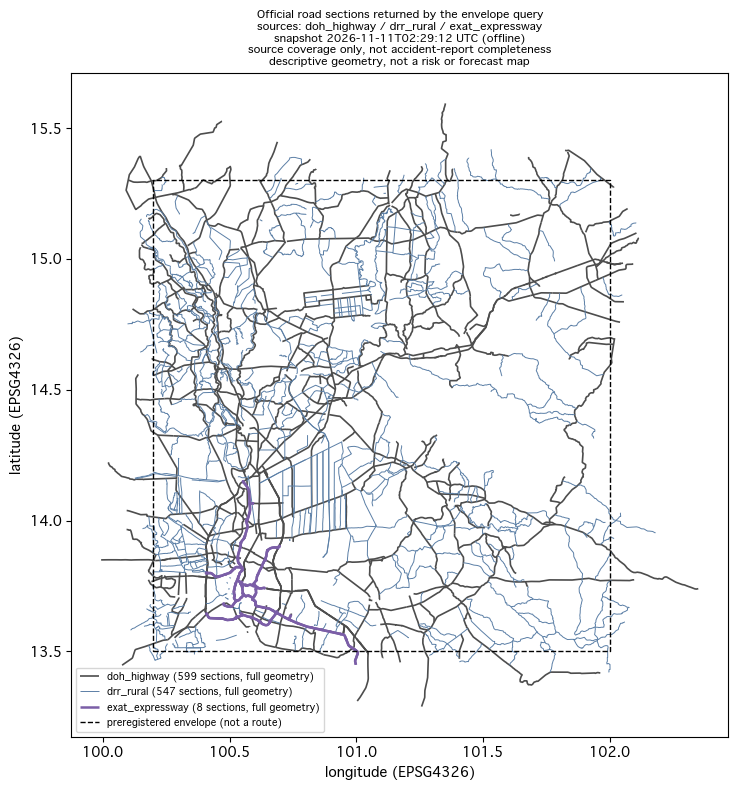

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


... (6 outputs left out)

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


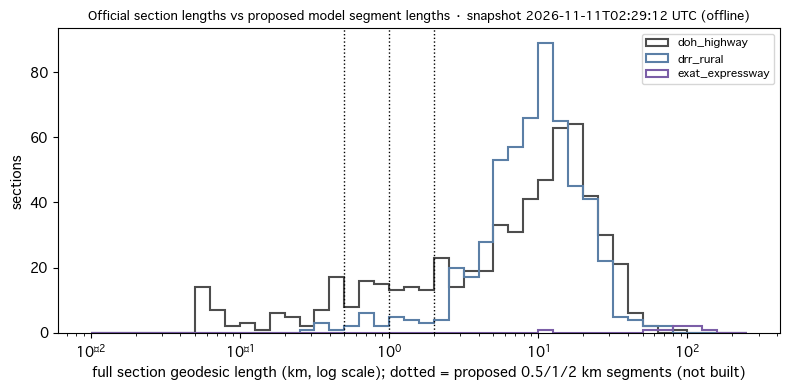

In [11]:
import matplotlib
import matplotlib.font_manager
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

_fonts = {f.name for f in matplotlib.font_manager.fontManager.ttflist}
matplotlib.rcParams['font.family'] = [f for f in CFG['figure_fonts'] if f in _fonts][:1] + ['DejaVu Sans']
PATHS['figure_dir'].mkdir(parents=True, exist_ok=True)
SNAP_LABEL = 'snapshot ' + str(TABLES['source_summary']['captured_first_utc'].min())[:19] + ' UTC (' + MODE + ')'
# neutral source-identity colours only (no red/amber/green): line colour never encodes risk
STYLE = {'doh_highway': ('#4d4d4d', 1.2), 'drr_rural': ('#5b7fa6', 0.7), 'exat_expressway': ('#7b5ea7', 1.8)}
env = CFG['preregistration']['envelope_epsg4326']

fig, ax = plt.subplots(figsize=(8, 8))
for sid, feats in GEO['full'].items():
    segs = [part for ft in feats for part in geojson_parts(ft['geometry'])]
    color, lw = STYLE.get(sid, ('#888888', 0.8))
    ax.add_collection(LineCollection(segs, colors=color, linewidths=lw, label=sid + ' (' + str(len(feats)) + ' sections, full geometry)'))
ax.plot([env[0], env[2], env[2], env[0], env[0]], [env[1], env[1], env[3], env[3], env[1]], 'k--', lw=1, label='preregistered envelope (not a route)')
ax.autoscale()
ax.set_aspect(1 / math.cos(math.radians((env[1] + env[3]) / 2)))
ax.set_xlabel('longitude (EPSG4326)')
ax.set_ylabel('latitude (EPSG4326)')
ax.set_title('Official road sections returned by the envelope query' + NL +
             'sources: ' + ' / '.join(s['id'] for s in CFG['sources']) + NL +
             SNAP_LABEL + NL +
             'source coverage only, not accident-report completeness' + NL +
             'descriptive geometry, not a risk or forecast map', fontsize=8)
ax.legend(loc='lower left', fontsize=7)
fig.tight_layout()
fig.savefig(PATHS['figure_dir'] / 'road_sections_overview.png', dpi=130)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for sid in ROWS['source_id'].unique():
    L = pd.to_numeric(ROWS.loc[ROWS['source_id'] == sid, 'length_full_m'], errors='coerce').dropna() / 1000
    if len(L):
        ax.hist(L.clip(lower=0.01), bins=[10 ** (k / 10) for k in range(-20, 25)], histtype='step', lw=1.5, color=STYLE.get(sid, ('#888888', 1))[0], label=sid)
for km in CFG['segment_length_candidates_km']:
    ax.axvline(km, color='k', ls=':', lw=1)
ax.set_xscale('log')
ax.set_xlabel('full section geodesic length (km, log scale); dotted = proposed 0.5/1/2 km segments (not built)')
ax.set_ylabel('sections')
ax.set_title('Official section lengths vs proposed model segment lengths · ' + SNAP_LABEL, fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(PATHS['figure_dir'] / 'section_length_distribution.png', dpi=130)
plt.show()


## 6 · Outputs และ acceptance manifest

ตารางสรุปและรายงานไทยเขียนเสมอ (ระบุสถานะ) แต่ `cache_manifest.json` และ `road_collection_manifest.json` เขียนแบบ atomic **เฉพาะเมื่อทุกแหล่งครบ** ข้อมูลบางส่วนจะไม่ได้ manifest และ cell นี้จะ raise

In [12]:
write_tables_and_derivatives(PATHS, TABLES, ROWS, GEO)
REPORT_TH = build_report_th(CFG, MODE, RESULTS, TABLES, DEPS, DISCOVERY, CACHE_SOURCE)
atomic_write_bytes(PATHS['report_dir'] / 'road_collection_report_th.md', REPORT_TH.encode('utf-8'))
PROTECTED_AFTER = hash_paths(BACKEND, CFG['protected_paths'])
CHANGED = sorted(k for k in set(PROTECTED_BEFORE) | set(PROTECTED_AFTER) if PROTECTED_BEFORE.get(k) != PROTECTED_AFTER.get(k))
if CHANGED:
    for sid in RESULTS:
        RESULTS[sid]['status'] = 'incomplete'
        RESULTS[sid]['problems'].append({'code': 'protected_input_changed', 'message': str(CHANGED[:5])})
EXTRA = {'protected_unchanged': not CHANGED, 'protected_files_hashed': sum(1 for v in PROTECTED_BEFORE.values() if v), 'python': platform.python_version(),
         'discovery_context': {k: DISCOVERY[k] for k in ('national_counts', 'pilot_counts', 'pilot_envelope_matches', 'checked_utc', 'note')}}
COMPLETE, STATUS = write_acceptance(PATHS, CFG, CFG_SHA, MODE, RESULTS, CACHE_MANIFEST, CACHE_SOURCE, DEPS, EXTRA)
display(Markdown(REPORT_TH))
print('report dir:', PATHS['report_dir'], '| row-level/derived:', PATHS['derived_dir'], '| protected changed:', len(CHANGED), '| status:', STATUS['status'])
if not COMPLETE:
    raise RoadCollectionError('collection INCOMPLETE: no acceptance manifest written. ' + ' | '.join(sid + ': ' + str(v.get('next_step')) for sid, v in RESULTS.items()))

# รายงานเก็บ geometry ถนนทางการ (notebook 17, V3 pilot envelope)

**สถานะ: COMPLETE (ครบทุกแหล่งในกรอบ query)**

- config: spatial_road_sources_v3.1 | แหล่ง (3): doh_highway, drr_rural, exat_expressway
- โหมด: offline | cache: /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/rerun-road-013a-online-001/data/v3/road_collection_v3_1/raw
- กรอบที่ลงทะเบียนไว้ก่อน: EPSG4326 [100.2, 13.5, 102.0, 15.3] (esriSpatialRelIntersects) เป็นกรอบนำร่องเก็บ geometry **ไม่ใช่เส้นทางที่คำนวณ** และไม่ครอบคลุม 6 จังหวัดทั้งหมด
- full snapshot = feature ทั้งหมดที่ query กรอบนี้คืน (รวมถนนที่ไม่เคยมีเหตุ) ไม่ใช่ถนนทั้งประเทศ; เก็บ section เต็มตามที่คืนมา ส่วนที่ตัดตามกรอบเป็น derivative แยก
- ความครอบคลุมของแหล่งถนน (ชั้นข้อมูลถนนทางการหนึ่งชั้นต่อหน่วยงาน DOH/DRR/EXAT) **ไม่ใช่** ความครบของรายงานอุบัติเหตุ ไม่ใช่ปริมาณการใช้ถนน (exposure) และไม่ใช่ความน่าจะเป็นของเหตุ
- จำนวนระดับประเทศ/นำร่องที่ manager สังเกตไว้เป็นบริบทเท่านั้น ไม่ใช่ค่าคาดหวัง (ค่าว่าง = manager ไม่ได้ query เช่น จำนวน EXAT ระดับประเทศ)

## จำนวน feature และการกระทบยอด object ID

| source_id | status | count_before | ids_before | pages_planned | pages_present | features_returned | unique_oid | count_after | inventory_stable | geometry_bytes | captured_first_utc | captured_last_utc | context_pilot_count_manager | context_national_count_manager |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| doh_highway | complete | 599 | 599 | 30 | 30 | 599 | 599 | 599 | True | 36369962 | 2026-11-11T02:29:12.170187+00:00 | 2026-11-11T02:29:19.966190+00:00 | 599 | 3044 |
| drr_rural | complete | 547 | 547 | 28 | 28 | 547 | 547 | 547 | True | 4733323 | 2026-11-11T02:29:20.629203+00:00 | 2026-11-11T02:29:29.437360+00:00 | 547 | 3700 |
| exat_expressway | complete | 8 | 8 | 1 | 1 | 8 | 8 | 8 | True | 3434022 | 2026-11-11T02:29:29.476780+00:00 | 2026-11-11T02:29:30.342523+00:00 | 8 |  |

ตรวจ: count = จำนวน ID (predicate เดียวกัน), ทุก batch คืน ID ครบตามที่ขอ ไม่มี ID ซ้ำ/เกิน, ไม่มี exceededTransferLimit, ทุกหน้า spatialReference 4326, count/IDs หลังดาวน์โหลดตรงกับก่อนดาวน์โหลด; object ID คือ objectIdField ของแต่ละ layer (EXAT ใช้ objectid_1 ไม่ใช่ objectid)

## ปัญหาที่พบ

_(ไม่มีข้อมูล)_

## คุณภาพ geometry (flag เท่านั้น ไม่ซ่อม ไม่ลบ ไม่ simplify)

| source_id | features | geojson_derivative_ok | geom_missing | curve_geometry | empty_or_short_part | nonfinite_coord | extra_dims | lon_out_of_range | lat_out_of_range | latlon_swap_suspect | outside_thailand_bbox | bbox_disjoint_envelope | clip_empty | features_with_dup_consecutive_vertices | multipart | shapely_invalid | not_simple | sections_with_length | total_full_km | total_clipped_km | median_full_m | p10_full_m | p90_full_m | max_full_m |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| doh_highway | 599 | 599 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 2 | 599 | 6685 | 5957 | 9073 | 490.1 | 2.51e+04 | 8.489e+04 |
| drr_rural | 547 | 547 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 4 | 547 | 6389 | 5987 | 1.002e+04 | 3283 | 2.158e+04 | 7.463e+04 |
| exat_expressway | 8 | 8 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 8 | 0 | 4 | 8 | 701.4 | 689.5 | 8.744e+04 | 4.085e+04 | 1.314e+05 | 1.486e+05 |

ความยาวคำนวณแบบ geodesic บน WGS84 (Vincenty, stdlib) ไม่ใช้ระยะ degree เป็นเมตร; pyproj 3.6.1 Geod.line_length on 1154 sections: max relative difference 1.61e-07

## section ทางการ เทียบ segment 0.5/1/2 กม. ที่เสนอ

section ของ DOH/DRR/EXAT เป็นช่วงหยาบตามระบบงานของหน่วยงาน ไม่ใช่ segment มาตรฐานของโมเดล ตารางนี้แสดงสัดส่วนเท่านั้น **ยังไม่ได้ตัด segment**

| source_id | proposed_segment_km | sections_with_length | share_sections_shorter | share_sections_longer |
|---|---|---|---|---|
| doh_highway | 0.5 | 599 | 0.1052 | 0.8948 |
| doh_highway | 1 | 599 | 0.172 | 0.828 |
| doh_highway | 2 | 599 | 0.2387 | 0.7613 |
| drr_rural | 0.5 | 547 | 0.0091 | 0.9909 |
| drr_rural | 1 | 547 | 0.0274 | 0.9726 |
| drr_rural | 2 | 547 | 0.0494 | 0.9506 |
| exat_expressway | 0.5 | 8 | 0 | 1 |
| exat_expressway | 1 | 8 | 0 | 1 |
| exat_expressway | 2 | 8 | 0 | 1 |

## หน่วยของ attribute (สมมติฐาน รอยืนยันจากเอกสารทางการ)

EXAT ไม่มี attribute กม./ความยาวที่กำหนดใน config (SHAPE__Length เป็นหน่วย degree ไม่ใช้เป็นเมตร)

| source_id | quantity | field | n_compared | share_in_band_m | median_ratio_m | share_in_band_km | median_ratio_km | hypothesis | status |
|---|---|---|---|---|---|---|---|---|---|
| doh_highway | length attribute | length | 585 | 0 | 0.001 | 0.9744 | 1 | consistent_with_km | hypothesis_pending_official_confirmation |
| doh_highway | abs(km_end - km_start) | km_end - km_start | 599 | 0.975 | 1 | 0 | 1000 | consistent_with_m | hypothesis_pending_official_confirmation |
| doh_highway | geometry length field | SHAPE__Length | 0 |  |  |  |  | units per layer geometryProperties: esriDecimalDegrees | not_metres_never_used_as_length |
| drr_rural | length attribute | length_gps | 514 | 0.0019 | 0.001 | 0.9066 | 0.9999 | consistent_with_km | hypothesis_pending_official_confirmation |
| drr_rural | length attribute | length_drr | 547 | 0 | 0.001 | 0.9744 | 0.9967 | consistent_with_km | hypothesis_pending_official_confirmation |
| drr_rural | abs(km_end - km_start) | km_end - km_start | 547 | 0.9744 | 0.9967 | 0 | 996.7 | consistent_with_m | hypothesis_pending_official_confirmation |
| exat_expressway | geometry length field | SHAPE__Length | 0 |  |  |  |  | units per layer geometryProperties: esriDecimalDegrees | not_metres_never_used_as_length |

## vintage / licence metadata

| source_id | item | field | n_present | min | max | note |
|---|---|---|---|---|---|---|
| doh_highway | snapshot capture (UTC) |  |  | 2026-11-11T02:29:12.170187+00:00 | 2026-11-11T02:29:19.966190+00:00 | current service state; not a 2021-2025 historical topology |
| doh_highway | layer lastEditDate | editingInfo |  |  |  | None = not published by the service |
| doh_highway | service/layer version | currentVersion |  | 11.5 |  | ArcGIS server version, not a data vintage |
| doh_highway | licence |  |  |  |  | pending: licence text of the MOT catalog resource was not captured; confirm on the catalog resource page before redistribution / copyrightText: '' |
| drr_rural | snapshot capture (UTC) |  |  | 2026-11-11T02:29:20.629203+00:00 | 2026-11-11T02:29:29.437360+00:00 | current service state; not a 2021-2025 historical topology |
| drr_rural | layer lastEditDate | editingInfo |  |  |  | None = not published by the service |
| drr_rural | service/layer version | currentVersion |  | 10.11 |  | ArcGIS server version, not a data vintage |
| drr_rural | licence |  |  |  |  | pending: licence text of the MOT catalog resource was not captured; confirm on the catalog resource page before redistribution / copyrightText: '' |
| drr_rural | date attribute | updated_date | 547 | 2025-01-22 | 2025-04-18 | meaning of the date (survey/update) per official documentation: pending |
| drr_rural | date attribute | survey_date | 0 |  |  | meaning of the date (survey/update) per official documentation: pending |
| drr_rural | year attribute | budget_year | 547 | 2569 | 2569 | calendar (BE/CE) and meaning pending confirmation |
| exat_expressway | snapshot capture (UTC) |  |  | 2026-11-11T02:29:29.476780+00:00 | 2026-11-11T02:29:30.342523+00:00 | current service state; not a 2021-2025 historical topology |
| exat_expressway | layer lastEditDate | editingInfo |  |  |  | None = not published by the service |
| exat_expressway | service/layer version | currentVersion |  | 11.5 |  | ArcGIS server version, not a data vintage |
| exat_expressway | licence |  |  |  |  | pending: licence text of the MOT catalog resource was not captured; confirm on the catalog resource page before redistribution / copyrightText: '' |

## ความครบของ attribute

| source_id | field | esri_type | n_features | n_null | n_blank_string | n_numeric_zero | share_missing |
|---|---|---|---|---|---|---|---|
| doh_highway | objectid | esriFieldTypeOID | 599 | 0 | 0 | 0 | 0 |
| doh_highway | road_code | esriFieldTypeString | 599 | 0 | 0 | 0 | 0 |
| doh_highway | road_name | esriFieldTypeString | 599 | 0 | 0 | 0 | 0 |
| doh_highway | section_co | esriFieldTypeString | 599 | 0 | 0 | 0 | 0 |
| doh_highway | section_na | esriFieldTypeString | 599 | 0 | 0 | 0 | 0 |
| doh_highway | km_start | esriFieldTypeInteger | 599 | 0 | 0 | 211 | 0 |
| doh_highway | km_end | esriFieldTypeInteger | 599 | 0 | 0 | 0 | 0 |
| doh_highway | length | esriFieldTypeDouble | 599 | 0 | 0 | 14 | 0 |
| doh_highway | SHAPE__Length | esriFieldTypeDouble | 599 | 0 | 0 | 0 | 0 |
| drr_rural | OBJECTID | esriFieldTypeOID | 547 | 0 | 0 | 0 | 0 |
| drr_rural | direction | esriFieldTypeString | 547 | 0 | 4 | 0 | 0.0073 |
| drr_rural | status | esriFieldTypeString | 547 | 0 | 0 | 0 | 0 |
| drr_rural | updated_date | esriFieldTypeDate | 547 | 0 | 0 | 0 | 0 |
| drr_rural | route_name | esriFieldTypeString | 547 | 0 | 0 | 0 | 0 |
| drr_rural | length_gps | esriFieldTypeDouble | 547 | 0 | 0 | 33 | 0 |
| drr_rural | length_drr | esriFieldTypeDouble | 547 | 0 | 0 | 0 | 0 |
| drr_rural | lane_width | esriFieldTypeDouble | 547 | 0 | 0 | 96 | 0 |
| drr_rural | user_name | esriFieldTypeString | 547 | 0 | 0 | 0 | 0 |
| drr_rural | road_code | esriFieldTypeString | 547 | 0 | 0 | 0 | 0 |
| drr_rural | link_id | esriFieldTypeInteger | 547 | 0 | 0 | 0 | 0 |
| drr_rural | sublink_id | esriFieldTypeInteger | 547 | 0 | 0 | 544 | 0 |
| drr_rural | budget_year | esriFieldTypeInteger | 547 | 0 | 0 | 0 | 0 |
| drr_rural | gid | esriFieldTypeInteger | 547 | 0 | 0 | 0 | 0 |
| drr_rural | km_start | esriFieldTypeInteger | 547 | 0 | 0 | 529 | 0 |
| drr_rural | km_end | esriFieldTypeInteger | 547 | 0 | 0 | 0 | 0 |
| drr_rural | sublink_revision | esriFieldTypeInteger | 547 | 23 | 0 | 284 | 0.042 |
| drr_rural | lane_count | esriFieldTypeInteger | 547 | 1 | 0 | 0 | 0.0018 |
| drr_rural | link_revision | esriFieldTypeInteger | 547 | 0 | 0 | 307 | 0 |
| drr_rural | survey_date | esriFieldTypeDate | 547 | 547 | 0 | 0 | 1 |
| exat_expressway | objectid_1 | esriFieldTypeOID | 8 | 0 | 0 | 0 | 0 |
| exat_expressway | objectid | esriFieldTypeInteger | 8 | 0 | 0 | 0 | 0 |
| exat_expressway | route | esriFieldTypeString | 8 | 0 | 0 | 0 | 0 |
| exat_expressway | centerline | esriFieldTypeString | 8 | 0 | 0 | 0 | 0 |
| exat_expressway | SHAPE__Length | esriFieldTypeDouble | 8 | 0 | 0 | 0 | 0 |

## ตาราง readiness

| check | source_id | status | evidence |
|---|---|---|---|
| preregistered_envelope | all | info | EPSG4326 [100.2, 13.5, 102.0, 15.3] esriSpatialRelIntersects; geometry pilot only, not a routed path, not all six candidate provinces |
| collection_complete | doh_highway | pass | complete |
| count_ids_pages_reconciled | doh_highway | pass | count 599, IDs 599, pages 30/30, unique features 599 |
| inventory_stable_pre_post | doh_highway | pass | count before 599, after 599; non-transactional caveat remains |
| crs_outsr_4326 | doh_highway | pass | every page spatialReference must be 4326; layer wkid 4326 |
| geometry_nonempty_finite_lines | doh_highway | pass | 0 features flagged (kept in raw, excluded only from the GeoJSON derivative); derivative ok 599 |
| lonlat_order_and_bounds | doh_highway | pass | swap suspects 0, outside Thailand box 0 |
| envelope_predicate_consistency | doh_highway | pass | bbox disjoint 0, empty clip 0 |
| geodesic_lengths | doh_highway | pass | WGS84 Vincenty (stdlib) on 599 sections; pyproj 3.6.1 Geod.line_length on 1154 sections: max relative difference 1.61e-07 |
| topology_simple_valid | doh_highway | review | not simple 2, invalid 0 (flag only, no repair) |
| units: length | doh_highway | pending | consistent_with_km (hypothesis_pending_official_confirmation) |
| units: km_end - km_start | doh_highway | pending | consistent_with_m (hypothesis_pending_official_confirmation) |
| units: SHAPE__Length | doh_highway | pending | units per layer geometryProperties: esriDecimalDegrees (not_metres_never_used_as_length) |
| vintage_historical_topology | doh_highway | pending | current snapshot only; does not prove the 2021-2025 road network |
| licence | doh_highway | pending | pending: licence text of the MOT catalog resource was not captured; confirm on the catalog resource page before redistribution |
| collection_complete | drr_rural | pass | complete |
| count_ids_pages_reconciled | drr_rural | pass | count 547, IDs 547, pages 28/28, unique features 547 |
| inventory_stable_pre_post | drr_rural | pass | count before 547, after 547; non-transactional caveat remains |
| crs_outsr_4326 | drr_rural | pass | every page spatialReference must be 4326; layer wkid 4326 |
| geometry_nonempty_finite_lines | drr_rural | pass | 0 features flagged (kept in raw, excluded only from the GeoJSON derivative); derivative ok 547 |
| lonlat_order_and_bounds | drr_rural | pass | swap suspects 0, outside Thailand box 0 |
| envelope_predicate_consistency | drr_rural | pass | bbox disjoint 0, empty clip 0 |
| geodesic_lengths | drr_rural | pass | WGS84 Vincenty (stdlib) on 547 sections; pyproj 3.6.1 Geod.line_length on 1154 sections: max relative difference 1.61e-07 |
| topology_simple_valid | drr_rural | review | not simple 4, invalid 0 (flag only, no repair) |
| units: length_gps | drr_rural | pending | consistent_with_km (hypothesis_pending_official_confirmation) |
| units: length_drr | drr_rural | pending | consistent_with_km (hypothesis_pending_official_confirmation) |
| units: km_end - km_start | drr_rural | pending | consistent_with_m (hypothesis_pending_official_confirmation) |
| vintage_historical_topology | drr_rural | pending | current snapshot only; does not prove the 2021-2025 road network |
| licence | drr_rural | pending | pending: licence text of the MOT catalog resource was not captured; confirm on the catalog resource page before redistribution |
| collection_complete | exat_expressway | pass | complete |
| count_ids_pages_reconciled | exat_expressway | pass | count 8, IDs 8, pages 1/1, unique features 8 |
| inventory_stable_pre_post | exat_expressway | pass | count before 8, after 8; non-transactional caveat remains |
| crs_outsr_4326 | exat_expressway | pass | every page spatialReference must be 4326; layer wkid 4326 |
| geometry_nonempty_finite_lines | exat_expressway | pass | 0 features flagged (kept in raw, excluded only from the GeoJSON derivative); derivative ok 8 |
| lonlat_order_and_bounds | exat_expressway | pass | swap suspects 0, outside Thailand box 0 |
| envelope_predicate_consistency | exat_expressway | pass | bbox disjoint 0, empty clip 0 |
| geodesic_lengths | exat_expressway | pass | WGS84 Vincenty (stdlib) on 8 sections; pyproj 3.6.1 Geod.line_length on 1154 sections: max relative difference 1.61e-07 |
| topology_simple_valid | exat_expressway | review | not simple 4, invalid 0 (flag only, no repair) |
| units: SHAPE__Length | exat_expressway | pending | units per layer geometryProperties: esriDecimalDegrees (not_metres_never_used_as_length) |
| vintage_historical_topology | exat_expressway | pending | current snapshot only; does not prove the 2021-2025 road network |
| licence | exat_expressway | pending | pending: licence text of the MOT catalog resource was not captured; confirm on the catalog resource page before redistribution |
| model_segments_0.5_1_2km | all | pending | official records are coarse sections; segmentation not built in this task |
| road_snapping_zero_labels_completeness | all | not_in_scope | no snapping, labels, accident-report completeness or route-level skill |
| routed_spu_khaoyai_path | all | not_in_scope | no route computed; the envelope is not a route |

## ข้อจำกัดที่ต้องอ่านคู่กัน

- ArcGIS REST queries are not transactional: count and IDs are re-queried after the download and must match, but an edit to the attributes or geometry of an existing OID between requests cannot be excluded
- snapshot = current service state at capture time; it does not prove the 2021-2025 road topology
- full official sections intersecting the envelope are kept as returned; the envelope-clipped geometry is a separate derivative
- national/pilot counts observed by the manager are context only, never expected values
- source coverage (one official road layer per configured agency, e.g. DOH/DRR/EXAT) is not accident-report completeness, road exposure or event probability
- official records are coarse road sections, not the proposed 0.5/1/2 km model segments (not built here)
- no road snapping, zero labels, accident-report completeness, model, risk score or route-level skill is evaluated; no SPU-Khao Yai route is computed

## Runbook

- VS Code: เลือก kernel .venv แล้ว Run All (offline ต้องมี cache ที่ตรวจครบของ config นี้ที่ backend/data/v3/road_collection_v3_1)
- Codex online: .venv/bin/python backend/scripts/run_spatial_road_collection.py --online --output-dir backend/rerun-road-<UTC>
- Codex offline ตรวจซ้ำ: .venv/bin/python backend/scripts/run_spatial_road_collection.py --output-dir backend/rerun-road-<UTC2> --cache-from backend/rerun-road-<UTC>/data/v3/road_collection_v3_1 --expect-manifest backend/rerun-road-<UTC>/reports/v3/road_collection_v3_1/road_collection_manifest.json
- raw/cache/GeoJSON อยู่ใต้ data/v3/road_collection_v3_1 (gitignored) ส่วน reports/v3/road_collection_v3_1 เก็บเฉพาะตารางสรุป รูป และ manifest
- cache ต้องมีชุดแหล่งตรงกับ config (doh_highway, drr_rural, exat_expressway); cache ของ config รุ่นก่อนที่มีแหล่งไม่ครบจะถูกปฏิเสธ ห้ามนำมาผสม
- ทุกครั้งใช้ output root ใหม่; การเปลี่ยนกรอบหรือ budget ต้องบันทึกใน config ก่อนดูผลโมเดลใด ๆ

## ขั้นต่อไป

- doh_highway: none: complete for the preregistered envelope
- drr_rural: none: complete for the preregistered envelope
- exat_expressway: none: complete for the preregistered envelope


report dir: /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/rerun-road-013a-offline-002/reports/v3/road_collection_v3_1 | row-level/derived: /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/rerun-road-013a-offline-002/data/v3/road_collection_v3_1/derived | protected changed: 0 | status: complete
